This notebook is a complementary notebook. It computes the figures that are not already computed in the presentation notebook.

# Libraries

In [1]:
# Needed to use the Sikhorn version of the library POT
!pip install POT


Defaulting to user installation because normal site-packages is not writeable


In [1]:

# Libraries for maths
import numpy as np
import random as rd
import scipy.optimize as opt
import scipy as sp
import pylab as pl
import ot

# Measuring time
import time
from time import perf_counter


#Libraries for plots
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

#Librairies for saving figures
import os

# Parameters set for picture esthetic
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "lines.linewidth": 2,
})

# Fixed parameters
Nmax = 100
Le = 1

# Default Parameters

In the following cell, you can choose the discrete parameters defining the optimal transport problems :
- The discrete sets $X$ and $Y$ of size $\mathcal{N}_x$ and $\mathcal{N}_y$
- The discrete Cost $\mathbf{C}$
- The marginals $\boldsymbol{\mu}_0$, $\boldsymbol{\mu}_1$, $\boldsymbol{\nu}_0$ and $\boldsymbol{\nu}_1$

Note that $\mathcal{N}_x$ and $\mathcal{N}_y$ should not be too large (typically < 150) in order to be able to solve the high-fidelity problem on a commodity laptop.

In [24]:
# Size of the High-fidelity problem
Nx, Ny = 100, 100

# Parameters of high-fidelity problem
#
Le = 1
X, Y = np.linspace(-Le,Le,Nx), np.linspace(-Le,Le,Ny)
## Discrete Cost C (quadratic cost)
C = (X**2).reshape(Nx,1)@np.ones((1,Ny)) + np.ones((Nx,1))@(Y**2).T.reshape(1,Ny) - 2*X.reshape(Nx,1)@Y.T.reshape(1,Ny)
c = np.matrix.flatten(C)

## Marginals (discrete gaussian measures, K0 = K1 = 2)
## Parameters of marginals
sigma_mu, sigma_nu = [0.5,0.5], [0.5,0.5]
m_mu, m_nu = [-Le/2,Le/2],  [-Le/2,Le/2]
K0, K1 = len(sigma_mu), len(sigma_nu)
mu0, mu1 = np.exp(-(X-m_mu[0]*np.ones((Nx)))**2/sigma_mu[0]**2), np.exp(-(X-m_mu[1]*np.ones((Nx)))**2/sigma_mu[1]**2)
nu0, nu1 = np.exp(-(Y-m_nu[0]*np.ones((Ny)))**2/sigma_nu[0]**2), np.exp(-(X-m_nu[1]*np.ones((Ny)))**2/sigma_nu[1]**2)
mu0, mu1, nu0, nu1 = mu0/np.sum(mu0), mu1/np.sum(mu1), nu0/np.sum(nu0), nu1/np.sum(nu1)

## Matrices for solving the high-fidelity problem
A= np.vstack([np.kron(np.eye(Nx),np.ones(Ny)), np.kron(np.ones(Nx), np.eye(Ny)) ])
Apos = np.eye(Nx*Ny, Nx*Ny)
bpos = np.zeros(Nx*Ny)


# Test set : a set of 50 random parameters on which we run the models to evaluate them (mean/worse time/precision)
#
# Test set : a set of 50 random parameters on which we run the models to evaluate them (mean/worse time/precision)
#
size_A_test= 100
A_test = np.zeros((size_A_test,2))

for ind in range(size_A_test):
    A_test[ind, 0] = rd.random()
    A_test[ind, 1] = rd.random()


# Table containing the different number of snapshots to take
nb_snap_tab = [2,4,6, 8 ,10]

# nb_snap_tab = [2,4,6,8,10, 15, 20]  #the table used for the experiments in the paper, takes a long time to compute

# Table containing the different values of epsilon for the Sinkhorn regularization we want to test
eps_tab = [1e-1, 5e-2, 1e-2, 5e-3]
#eps_tab = [1e-1, 5e-2, 1e-2]

# Time and precision analysis, for Kx = Ky = 2

## Visual comparison on an example

In [25]:
save_dir = "saved_snapshots"
os.makedirs(save_dir, exist_ok=True)

nb_snap_tab = [2,4,6,8,10,15,20]
options = {'dual_feasibility_tolerance': 1e-10, 'primal_feasibility_tolerance': 1e-10}

# Snapshots for each nb_snap, kept for the test cell
bases = {}
time_tab = np.zeros(len(nb_snap_tab))

for ind_snap, nb_snap in enumerate(nb_snap_tab):
    # Grid
    nb_snap_mu, nb_snap_nu = nb_snap, nb_snap
    P = nb_snap_mu * nb_snap_nu
    A_train = np.zeros((2,P))
    A_train[0,:] = np.matrix.flatten(np.ones((nb_snap_nu, 1))@np.reshape(np.linspace(0,1,nb_snap_mu), (1,nb_snap_mu)))
    A_train[1,:] = np.matrix.flatten(np.reshape(np.linspace(0,1,nb_snap_nu), (nb_snap_nu,1))@np.ones((1, nb_snap_mu)))

    # Building K (does not require to do snapshots)
    K = np.vstack([A_train, np.ones(P)])

    # Building W^Tc (snapshots) -- loaded from disk if already computed
    filename = os.path.join(save_dir, f"snapshots_LP_{nb_snap}.npz")
    if os.path.exists(filename):
        data = np.load(filename)
        Wc_LP, P_HF = data["Wc_LP"], data["P_HF"]
        time_snap = float(data["time_snap"]) if "time_snap" in data else np.nan
        print(f"nb_snap = {nb_snap}: snapshots loaded from {filename} (computed in {time_snap:.2f} s)")
    else:
        Wc_LP = np.zeros(P)
        P_HF = np.zeros((Nx*Ny, P))
        t_start = time.perf_counter()
        for p in range(P):
            a_mu, a_nu = A_train[0,p], A_train[1, p]
            mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
            munu = np.concatenate([mu,nu])
            res = opt.linprog(c, A_ub=- Apos, b_ub=bpos, A_eq=A, b_eq=munu, bounds=(None, None), x0=None, method='highs-ds', options=options)
            Wc_LP[p] = res.fun
            P_HF[:,p] = np.matrix.flatten(res.x)
        time_snap = time.perf_counter() - t_start
        np.savez(filename, Wc_LP=Wc_LP, P_HF=P_HF, A_train=A_train, time_snap=time_snap)
        print(f"nb_snap = {nb_snap}: {P} snapshots computed in {time_snap:.2f} s, saved to {filename}")

    time_tab[ind_snap] = time_snap
    bases[nb_snap] = {"Wc_LP": Wc_LP, "P_HF": P_HF, "K": K, "P": P}

nb_snap = 2: snapshots loaded from saved_snapshots/snapshots_LP_2.npz (computed in 4.03 s)
nb_snap = 4: snapshots loaded from saved_snapshots/snapshots_LP_4.npz (computed in 16.25 s)
nb_snap = 6: snapshots loaded from saved_snapshots/snapshots_LP_6.npz (computed in 36.54 s)
nb_snap = 8: snapshots loaded from saved_snapshots/snapshots_LP_8.npz (computed in 65.17 s)
nb_snap = 10: snapshots loaded from saved_snapshots/snapshots_LP_10.npz (computed in 101.06 s)
nb_snap = 15: snapshots loaded from saved_snapshots/snapshots_LP_15.npz (computed in 227.97 s)
nb_snap = 20: snapshots loaded from saved_snapshots/snapshots_LP_20.npz (computed in 404.03 s)


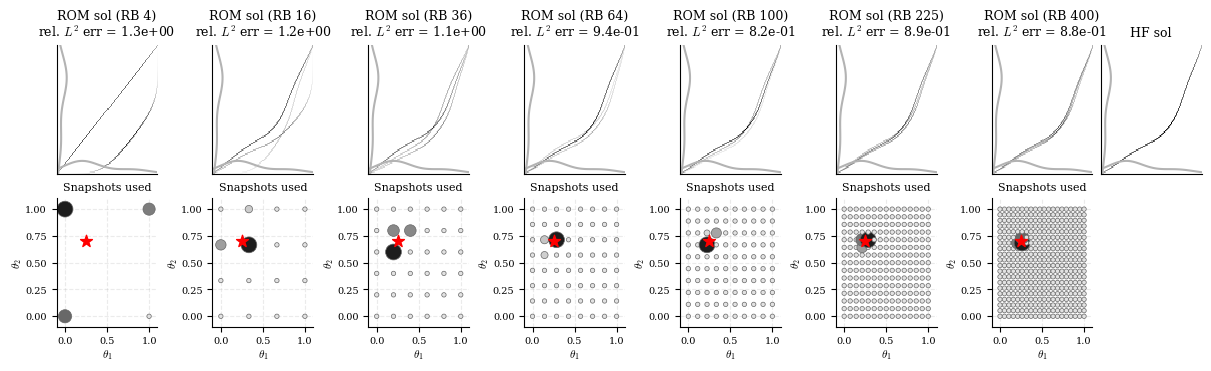

In [26]:
# Parameter chosen for the test
alpha_ex = [0.25, 0.7]

# --- Reduced solutions for each basis ---
P_tab = np.zeros((Nx*Ny, len(nb_snap_tab)))
RB_P_tab = np.zeros((Nx*Ny, len(nb_snap_tab)))

for ind_snap, nb_snap in enumerate(nb_snap_tab):
    b = bases[nb_snap]
    res = opt.linprog(b["Wc_LP"], A_ub=-np.eye(b["P"]), b_ub=np.zeros(b["P"]), A_eq=b["K"], b_eq=np.append(alpha_ex, 1),
                      bounds=(None, None), method='highs-ds', options=options)
    P_tab[:, ind_snap] = b["P_HF"] @ res.x
    RB_P_tab[:b["P"], ind_snap] = res.x

# --- High-fidelity reference for the example ---
mu = (1 - alpha_ex[0]) * mu0 + alpha_ex[0] * mu1
nu = (1 - alpha_ex[1]) * nu0 + alpha_ex[1] * nu1
res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=np.concatenate([mu, nu]),
                  bounds=(None, None), method='highs-ds', options=options)
P_HF_ref = res.x

# --- Plot ---
normal = 0.2      # height of the marginals drawn on the axes
gamma = 0.5       # contrast enhancement for the transport plans
grey_light = "0.7"

# All plans to display (ROM then HF), clipped at 0 to avoid NaN with **gamma
plans = [np.maximum(P_tab[:, i], 0)**gamma for i in range(len(nb_snap_tab))] + [np.maximum(P_HF_ref, 0)**gamma]
# Relative L2 error of each ROM solution w.r.t. the HF solution
errors = [np.linalg.norm(P_tab[:, i] - P_HF_ref) / np.linalg.norm(P_HF_ref) for i in range(len(nb_snap_tab))]

titles = [f"ROM sol (RB {n**2})\nrel. $L^2$ err = {err:.1e}" for n, err in zip(nb_snap_tab, errors)] + ["HF sol"]
vmax = max(plan.max() for plan in plans)   # common colour scale

plt.close("all")
n_cols = len(plans)
fig, axes = plt.subplots(2, n_cols, figsize=(12, 3.6), constrained_layout=True)

# Row 1: transport plans with marginals
for ax, plan, title in zip(axes[0], plans, titles):
    ax.imshow(np.reshape(plan, (Nx, Ny)), origin="lower", extent=[X.min(), X.max(), Y.min(), Y.max()],
              cmap="Greys", vmin=0, vmax=vmax, aspect="auto", interpolation="nearest")
    ax.plot(X, mu / mu.max() * normal - Le, color=grey_light, lw=1.5)
    ax.plot(nu / nu.max() * normal - Le, Y, color=grey_light, lw=1.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=9)

# Row 2: training parameters, sized and coloured by their weight in the ROM solution
for ind_snap, nb_snap in enumerate(nb_snap_tab):
    b = bases[nb_snap]
    A_train = b["K"][:2]                       # training grid (first two rows of K)
    weights = RB_P_tab[:b["P"], ind_snap]
    w = weights / (weights.max() + 1e-12)      # relative importance in [0, 1]

    ax = axes[1, ind_snap]
    ax.scatter(A_train[0], A_train[1], color=plt.cm.Greys(0.2 + 0.7 * w), s=10 + 120 * w,
               edgecolors="0.4", linewidths=0.5, zorder=2)
    ax.scatter(*alpha_ex, color="red", marker="*", s=80, zorder=3)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel(r"$\theta_1$", fontsize=8, labelpad=1)
    ax.set_ylabel(r"$\theta_2$", fontsize=8, labelpad=1)
    ax.tick_params(labelsize=7)
    ax.set_title("Snapshots used", fontsize=8)

axes[1, -1].axis("off")   # no snapshots for the HF column

# Save the figure
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)
fig_name = f"RB_vs_HF_alpha_{alpha_ex[0]}_{alpha_ex[1]}"
fig.savefig(os.path.join(fig_dir, fig_name + ".pdf"), bbox_inches="tight")
fig.savefig(os.path.join(fig_dir, fig_name + ".png"), dpi=300, bbox_inches="tight")

plt.show()

## Comparison time and precision between Sinkhorn and reduced-order model

### Computations

In [28]:
# Resolution of the HF problem with linear programming solver (LP)

# Reference values on the test set: optimal value, transport plan and solving time
filename = os.path.join(save_dir, f"HF_test_{size_A_test}.npz")

LP_val = np.zeros(size_A_test)
LP_plan = np.zeros((Nx*Ny, size_A_test))
LP_time = np.zeros(size_A_test)

for k, (a_mu, a_nu) in enumerate(A_test):
    t_start = perf_counter()
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1    
    res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=np.concatenate([mu, nu]),
                 bounds=(None, None), method='highs-ds', options=options)
    LP_time[k] = perf_counter() - t_start
    if not res.success:
        print(f"Warning: LP failed for alpha = ({a_mu:.3f}, {a_nu:.3f}): {res.message}")
    LP_val[k] = res.fun
    LP_plan[:, k] = res.x

np.savez(filename, LP_val=LP_val, LP_plan=LP_plan, LP_time=LP_time, A_test=A_test)
print(f"HF test results computed in {LP_time.sum():.1f} s, saved to {filename}")

print(f"Mean HF solving time: {LP_time.mean():.3e} s")

HF test results computed in 101.6 s, saved to saved_snapshots/HF_test_100.npz
Mean HF solving time: 1.016e+00 s


In [29]:
# Resolution of the HF problem with Sinkhorn (S)
Nmax = 1000 #maximum number of iteration in Sinkhorn for the hand made algorithm

# Results for each epsilon: time gain w.r.t. LP and error on the optimal value
S_time_gain_mean, S_time_gain_min = np.zeros(len(eps_tab)), np.zeros(len(eps_tab))
S_err_mean, S_err_max = np.zeros(len(eps_tab)), np.zeros(len(eps_tab))

for ind_eps, eps in enumerate(eps_tab):
    K_eps = np.exp(-C/eps)   # Gibbs kernel (independent of alpha)
    # KC = K_eps * C         # for the hand-made Sinkhorn

    S_time = np.zeros(size_A_test)
    S_val = np.zeros(size_A_test)

    for k, (a_mu, a_nu) in enumerate(A_test):
        t_start = perf_counter()
        mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1

        # # Sinkhorn made by hand
        # g = np.ones(Ny)/Ny
        # t, err = 0, 1
        # while t <= Nmax and err > 1e-6:
        #     f = mu / (K_eps@g)
        #     g = nu / (K_eps.T@f)
        #     t += 1
        #     err = np.max(np.abs(f*(K_eps@g) - mu))
        # S_val[k] = f @ KC @ g
        # #------------

        # Sinkhorn from library
        S_val[k] = ot.sinkhorn2(mu, nu, C, reg=eps)
        #-----

        S_time[k] = perf_counter() - t_start

    time_gain = LP_time / S_time
    err = np.abs(LP_val - S_val)   # W2_eps
    S_time_gain_mean[ind_eps], S_time_gain_min[ind_eps] = time_gain.mean(), time_gain.min()
    S_err_mean[ind_eps], S_err_max[ind_eps] = err.mean(), err.max()

In [30]:
# Resolution of the Reduced Basis (RB) problem (snapshots taken from `bases`)

# Results for each basis size: time gain w.r.t. LP, error on the optimal value and on the plan
RB_time_gain_mean, RB_time_gain_min = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_err_mean, RB_err_max, RB_err_min = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_L2_mean, RB_L2_max = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_time_mean = np.zeros(len(nb_snap_tab))

for ind_snap, nb_snap in enumerate(nb_snap_tab):
    b = bases[nb_snap]
    A_ub_RB, b_ub_RB = -np.eye(b["P"]), np.zeros(b["P"])   # positivity constraints (independent of alpha)

    RB_time = np.zeros(size_A_test)
    RB_val = np.zeros(size_A_test)
    RB_L2 = np.zeros(size_A_test)

    for k, (a_mu, a_nu) in enumerate(A_test):
        t_start = perf_counter()
        res = opt.linprog(b["Wc_LP"], A_ub=A_ub_RB, b_ub=b_ub_RB, A_eq=b["K"], b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        RB_time[k] = perf_counter() - t_start
        RB_val[k] = res.fun

        # Relative L2 error on the transport plan (not timed)
        RB_L2[k] = np.linalg.norm(b["P_HF"] @ res.x - LP_plan[:, k]) / np.linalg.norm(LP_plan[:, k])

    time_gain = LP_time / RB_time
    err = np.abs(LP_val - RB_val)
    RB_time_mean[ind_snap] = RB_time.mean()
    RB_time_gain_mean[ind_snap], RB_time_gain_min[ind_snap] = time_gain.mean(), time_gain.min()
    RB_err_mean[ind_snap], RB_err_max[ind_snap], RB_err_min[ind_snap] = err.mean(), err.max(), err.min()
    RB_L2_mean[ind_snap], RB_L2_max[ind_snap] = RB_L2.mean(), RB_L2.max()

In [31]:
## W2 distance between two transport plans, seen as measures on X x Y
def plan_to_measure(plan_vec, tol=1e-12):
    """support points (x_i, y_j) and normalized weights of a flattened plan (row-major: index i*Ny + j)"""
    P = np.maximum(plan_vec.reshape(Nx, Ny), 0)          # removes tiny negative round-off
    I, J = np.nonzero(P > tol*P.max())                   # keep only the support (plans are sparse)
    pts = np.hstack([X.reshape(Nx, -1)[I], Y.reshape(Ny, -1)[J]])
    w = P[I, J]
    return pts, w/w.sum()

def w2_plans(plan1, plan2):
    x1, w1 = plan_to_measure(plan1)
    x2, w2 = plan_to_measure(plan2)
    M = ot.dist(x1, x2)                                  # squared Euclidean cost on X x Y
    return np.sqrt(max(ot.emd2(w1, w2, M, numItermax=10**7), 0))

In [38]:
# Errors for the alpha of the figure, for every basis
a_mu, a_nu = 0.25, 0.7
mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=np.concatenate([mu, nu]),
                  bounds=(None, None), method='highs-ds', options=options)
plan_HF = res.x

def bary_map(plan):
    """barycentric transport map T(x_i) = sum_j pi_ij y_j / sum_j pi_ij, and the x-marginal"""
    P = np.maximum(plan.reshape(Nx, Ny), 0)
    m = P.sum(axis=1)
    return (P @ Y.reshape(Ny)) / np.maximum(m, 1e-300), m

T_HF, m_HF = bary_map(plan_HF)
for nb_snap in nb_snap_tab:
    b = bases[nb_snap]
    r = opt.linprog(b["Wc_LP"], A_ub=-np.eye(b["P"]), b_ub=np.zeros(b["P"]), A_eq=b["K"],
                    b_eq=np.array([a_mu, a_nu, 1.]), bounds=(None, None), method='highs-ds', options=options)
    plan_RB = b["P_HF"] @ r.x
    T_RB, _ = bary_map(plan_RB)
    map_err = np.sqrt(np.sum(m_HF * (T_RB - T_HF)**2))          # || T_RB - T_HF ||_{L2(mu)}
    print(f"{nb_snap**2:4d} snapshots   W2 = {w2_plans(plan_RB, plan_HF):.3e}   map error = {map_err:.3e}")

   4 snapshots   W2 = 2.707e-01   map error = 2.025e-01
  16 snapshots   W2 = 9.209e-02   map error = 2.723e-02
  36 snapshots   W2 = 4.864e-02   map error = 1.417e-02
  64 snapshots   W2 = 2.998e-02   map error = 4.362e-03
 100 snapshots   W2 = 2.035e-02   map error = 4.010e-03
 225 snapshots   W2 = 1.933e-02   map error = 2.786e-03
 400 snapshots   W2 = 1.635e-02   map error = 1.919e-03


In [40]:
# Resolution of the Reduced Basis (RB) problem (snapshots taken from `bases`)

# Results for each basis size: time gain w.r.t. LP, error on the optimal value and W2 error on the plan
RB_time_gain_mean, RB_time_gain_min = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_err_mean, RB_err_max, RB_err_min = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_W2_mean, RB_W2_max = np.zeros(len(nb_snap_tab)), np.zeros(len(nb_snap_tab))
RB_time_mean = np.zeros(len(nb_snap_tab))

for ind_snap, nb_snap in enumerate(nb_snap_tab):
    b = bases[nb_snap]
    A_ub_RB, b_ub_RB = -np.eye(b["P"]), np.zeros(b["P"])   # positivity constraints (independent of alpha)

    RB_time = np.zeros(size_A_test)
    RB_val = np.zeros(size_A_test)
    RB_W2 = np.zeros(size_A_test)

    for k, (a_mu, a_nu) in enumerate(A_test):
        t_start = perf_counter()
        res = opt.linprog(b["Wc_LP"], A_ub=A_ub_RB, b_ub=b_ub_RB, A_eq=b["K"], b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        RB_time[k] = perf_counter() - t_start
        RB_val[k] = res.fun

        # W2 distance between the RB and LP transport plans (not timed)
        RB_W2[k] = w2_plans(b["P_HF"] @ res.x, LP_plan[:, k])

    time_gain = LP_time / RB_time
    err = np.abs(LP_val - RB_val)
    RB_time_mean[ind_snap] = RB_time.mean()
    RB_time_gain_mean[ind_snap], RB_time_gain_min[ind_snap] = time_gain.mean(), time_gain.min()
    RB_err_mean[ind_snap], RB_err_max[ind_snap], RB_err_min[ind_snap] = err.mean(), err.max(), err.min()
    RB_W2_mean[ind_snap], RB_W2_max[ind_snap] = RB_W2.mean(), RB_W2.max()

### Visualisation

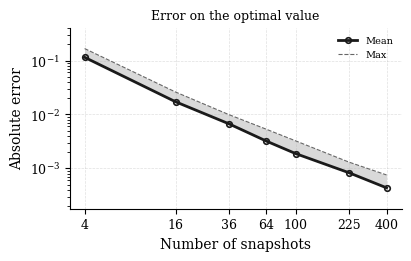

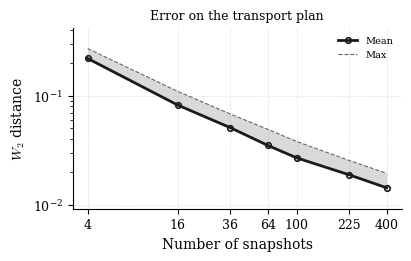

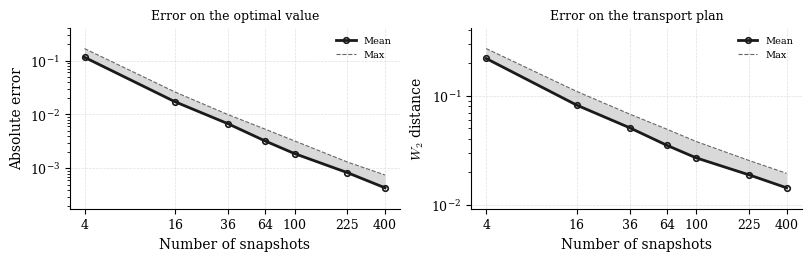

In [41]:
# Evolution of the RB errors with respect to the number of snapshots
import matplotlib.ticker as mticker
def plot_error(ax, x, err_mean, err_max, ylabel, title):
    """Mean (solid) and max (dashed) error, log-log scale."""
    ax.fill_between(x, err_mean, err_max, color="0.85", lw=0)
    ax.plot(x, err_mean, color="0.1", lw=2, marker="o", ms=4, mfc="none", mew=1.2, label="Mean")
    ax.plot(x, err_max, color="0.4", lw=0.8, ls="--", label="Max")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(x)
    ax.xaxis.set_minor_locator(mticker.NullLocator())   # x: only the snapshot numbers
    ax.margins(y=0.15)                                   # some room above/below the curves
    ax.set_xlabel("Number of snapshots")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=9)
    ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=7)

plt.close("all")
x = np.array(nb_snap_tab)**2   # number of snapshots

# one figure per error
for err_mean, err_max, ylabel, title, name in [
    (RB_err_mean, RB_err_max, "Absolute error", "Error on the optimal value", "RB_error_value"),
    (RB_W2_mean, RB_W2_max, "$W_2$ distance", "Error on the transport plan", "RB_error_plan"),
]:
    fig, ax = plt.subplots(figsize=(4, 2.5), constrained_layout=True)
    plot_error(ax, x, err_mean, err_max, ylabel, title)
    fig.savefig(os.path.join(fig_dir, name + ".pdf"), bbox_inches="tight")
    plt.show()

# both errors side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 2.5), constrained_layout=True)
plot_error(axes[0], x, RB_err_mean, RB_err_max,
           ylabel="Absolute error", title="Error on the optimal value")
plot_error(axes[1], x, RB_W2_mean, RB_W2_max,
           ylabel="$W_2$ distance", title="Error on the transport plan")
fig.savefig(os.path.join(fig_dir, "RB_errors_vs_snapshots.pdf"), bbox_inches="tight")
plt.show()

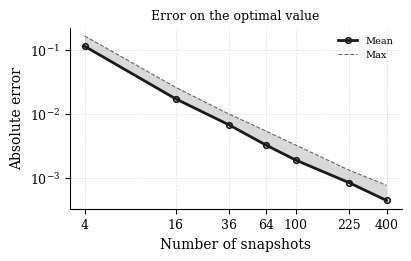

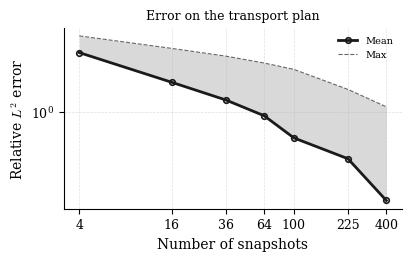

In [34]:
# Evolution of the RB errors with respect to the number of snapshots

def plot_error(ax, x, err_mean, err_max, ylabel, title):
    """Mean (solid) and max (dashed) error, log-log scale."""
    ax.fill_between(x, err_mean, err_max, color="0.85", lw=0)
    ax.plot(x, err_mean, color="0.1", lw=2, marker="o", ms=4, mfc="none", mew=1.2, label="Mean")
    ax.plot(x, err_max, color="0.4", lw=0.8, ls="--", label="Max")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(x)
    ax.minorticks_off()
    ax.set_xlabel("Number of snapshots")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=9)
    ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=7)

plt.close("all")
x = np.array(nb_snap_tab)**2

for err_mean, err_max, ylabel, title, name in [
    (RB_err_mean, RB_err_max, "Absolute error", "Error on the optimal value", "RB_error_value"),
    (RB_L2_mean, RB_L2_max, "Relative $L^2$ error", "Error on the transport plan", "RB_error_plan"),
]:
    fig, ax = plt.subplots(figsize=(4, 2.5), constrained_layout=True)
    plot_error(ax, x, err_mean, err_max, ylabel, title)
    fig.savefig(os.path.join(fig_dir, name + ".pdf"), bbox_inches="tight")
    plt.show()
x = np.array(nb_snap_tab)**2   # number of snapshots

plot_error(axes[0], x, RB_err_mean, RB_err_max,
           ylabel="Absolute error", title="Error on the optimal value")
plot_error(axes[1], x, RB_L2_mean, RB_L2_max,
           ylabel="Relative $L^2$ error", title="Error on the transport plan")

fig.savefig(os.path.join(fig_dir, "RB_errors_vs_snapshots.pdf"), bbox_inches="tight")
plt.show()

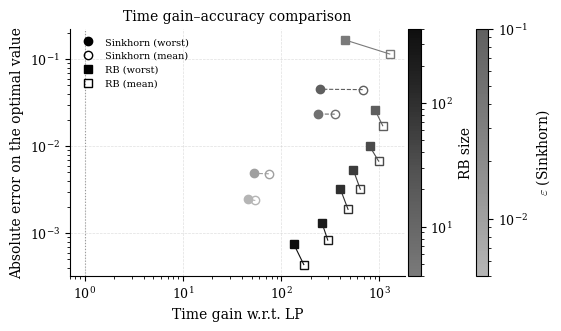

In [42]:
# Time gain / error trade-off w.r.t. the HF (LP) problem: RB vs Sinkhorn

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=256):
    return mcolors.LinearSegmentedColormap.from_list(f"{cmap.name}_trunc", cmap(np.linspace(minval, maxval, n)))

def plot_method(ax, gain_mean, gain_min, err_mean, err_max, params, cmap, norm, marker, ls):
    """For each parameter: segment from mean to worst case, filled marker = worst, empty = mean."""
    for p, gmean, gmin, emean, emax in zip(params, gain_mean, gain_min, err_mean, err_max):
        col = cmap(norm(p))
        ax.plot([gmean, gmin], [emean, emax], ls=ls, lw=0.8, color=col)
        ax.plot(gmin, emax, marker=marker, color=col, ls="none")
        ax.plot(gmean, emean, marker=marker, color=col, mfc="none", ls="none")

plt.close("all")
fig, ax = plt.subplots(figsize=(5.5, 3.2), constrained_layout=True)

# Grayscale colormaps and normalizations (log scale for both parameters)
cmap_S = truncate_colormap(plt.cm.Greys, 0.4, 0.7)
cmap_RB = truncate_colormap(plt.cm.Greys, 0.6, 0.95)
rb_sizes = np.array(nb_snap_tab)**2
norm_S = mcolors.LogNorm(vmin=min(eps_tab), vmax=max(eps_tab))
norm_RB = mcolors.LogNorm(vmin=rb_sizes.min(), vmax=rb_sizes.max())

plot_method(ax, S_time_gain_mean, S_time_gain_min, S_err_mean, S_err_max, eps_tab, cmap_S, norm_S, marker="o", ls="--")
plot_method(ax, RB_time_gain_mean, RB_time_gain_min, RB_err_mean, RB_err_max, rb_sizes, cmap_RB, norm_RB, marker="s", ls="-")

# No gain w.r.t. LP
ax.axvline(1, color="0.6", lw=0.8, ls=":")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Time gain w.r.t. LP")
ax.set_ylabel("Absolute error on the optimal value")
ax.set_title("Time gain–accuracy comparison", fontsize=10)
ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Legend with neutral (black) entries: colour is explained by the colorbars
legend_handles = [
    mpl.lines.Line2D([], [], marker="o", color="k", ls="none", label="Sinkhorn (worst)"),
    mpl.lines.Line2D([], [], marker="o", color="k", mfc="none", ls="none", label="Sinkhorn (mean)"),
    mpl.lines.Line2D([], [], marker="s", color="k", ls="none", label="RB (worst)"),
    mpl.lines.Line2D([], [], marker="s", color="k", mfc="none", ls="none", label="RB (mean)"),
]
ax.legend(handles=legend_handles, frameon=False, fontsize=7, loc="upper left")

# Colorbars (handled by constrained_layout)
fig.colorbar(mpl.cm.ScalarMappable(norm=norm_S, cmap=cmap_S), ax=ax, pad=0.01, fraction=0.04, label=r"$\varepsilon$ (Sinkhorn)")
fig.colorbar(mpl.cm.ScalarMappable(norm=norm_RB, cmap=cmap_RB), ax=ax, pad=0.01, fraction=0.04, label="RB size")

fig.savefig(os.path.join(fig_dir, "time_precision.pdf"), bbox_inches="tight")
plt.show()

In [47]:
# Break-even number of queries: T_snap + N * t_RB = N * t_LP

ERR = 'value'                                 # 'W2': W2 error on the plan, 'value': error on the optimal value
err_mean, err_max = (RB_W2_mean, RB_W2_max) if ERR == 'W2' else (RB_err_mean, RB_err_max)

t_LP = LP_time.mean()                      # mean HF (LP) solving time on the test set
rb_sizes = np.array(nb_snap_tab)**2

N_star = np.full(len(nb_snap_tab), np.inf)
for i in range(len(nb_snap_tab)):
    if RB_time_mean[i] < t_LP:             # otherwise RB never pays back
        N_star[i] = np.ceil(time_tab[i] / (t_LP - RB_time_mean[i]))

# Readable table
print(f"Mean LP time: {t_LP:.3e} s   (errors: {ERR})\n")
print(f"{'Snapshots':>10} | {'Offline (s)':>12} | {'Online (s)':>10} | {'break-even N*':>8} | {'Time gain':>10} | {'Mean err':>10} | {'Max err':>10}")
print("-" * 88)
for n, T, t, N, g, em, eM in zip(rb_sizes, time_tab, RB_time_mean, N_star, RB_time_gain_mean, err_mean, err_max):
    print(f"{n:>10} | {T:>12.2f} | {t:>10.2e} | {N:>8.0f} | {g:>10.0f} | {em:>10.2e} | {eM:>10.2e}")

# LaTeX rows, ready to paste into the table below
print("\n% LaTeX rows")
for n, T, t, N, g, em, eM in zip(rb_sizes, time_tab, RB_time_mean, N_star, RB_time_gain_mean, err_mean, err_max):
    print(f"{n} & {T:.2f} & {t:.2e} & {N:.0f} & {g:.0f} & {em:.2e} & {eM:.2e} \\\\")

Mean LP time: 1.016e+00 s   (errors: value)

 Snapshots |  Offline (s) | Online (s) | break-even N* |  Time gain |   Mean err |    Max err
----------------------------------------------------------------------------------------
         4 |         4.03 |   8.04e-04 |        4 |       1280 |   1.15e-01 |   1.67e-01
        16 |        16.25 |   9.39e-04 |       17 |       1085 |   1.72e-02 |   2.61e-02
        36 |        36.54 |   1.04e-03 |       36 |        985 |   6.74e-03 |   9.96e-03
        64 |        65.17 |   1.59e-03 |       65 |        641 |   3.20e-03 |   5.31e-03
       100 |       101.06 |   2.11e-03 |      100 |        481 |   1.88e-03 |   3.24e-03
       225 |       227.97 |   3.40e-03 |      226 |        299 |   8.32e-04 |   1.31e-03
       400 |       404.03 |   5.98e-03 |      400 |        170 |   4.36e-04 |   7.55e-04

% LaTeX rows
4 & 4.03 & 8.04e-04 & 4 & 1280 & 1.15e-01 & 1.67e-01 \\
16 & 16.25 & 9.39e-04 & 17 & 1085 & 1.72e-02 & 2.61e-02 \\
36 & 36.54 & 1.04e-0

# Error estimation

## Building error estimation + analysis

In [31]:
# Error estimation: dual potentials at the snapshots

# --- Dual potentials (phi, psi) at each training parameter, loaded from disk if already computed ---
for nb_snap in nb_snap_tab:
    b = bases[nb_snap]
    A_train = b["K"][:2]                      # training grid (same order as the snapshots)
    filename = os.path.join(save_dir, f"duals_LP_{nb_snap}.npz")

    if os.path.exists(filename):
        data = np.load(filename)
        phi_LP, psi_LP, time_dual = data["phi_LP"], data["psi_LP"], float(data["time_dual"])
        print(f"nb_snap = {nb_snap}: dual potentials loaded from {filename}")
    else:
        phi_LP, psi_LP = np.zeros((b["P"], Nx)), np.zeros((b["P"], Ny))
        t_start = perf_counter()
        for p, (a_mu, a_nu) in enumerate(A_train.T):
            mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
            res = opt.linprog(-np.concatenate([mu, nu]), A_ub=A.T, b_ub=c, bounds=(None, None),
                              method='highs-ds', options=options)
            if not res.success:
                print(f"Warning: dual LP failed for alpha = ({a_mu:.3f}, {a_nu:.3f}): {res.message}")
            phi_LP[p], psi_LP[p] = res.x[:Nx], res.x[Nx:]
        time_dual = perf_counter() - t_start
        np.savez(filename, phi_LP=phi_LP, psi_LP=psi_LP, time_dual=time_dual, A_train=A_train)
        print(f"nb_snap = {nb_snap}: {b['P']} dual LPs solved in {time_dual:.2f} s, saved to {filename}")

    b["phi_LP"], b["psi_LP"], b["time_dual"] = phi_LP, psi_LP, time_dual



nb_snap = 2: 4 dual LPs solved in 0.26 s, saved to saved_snapshots/duals_LP_2.npz
nb_snap = 4: 16 dual LPs solved in 1.09 s, saved to saved_snapshots/duals_LP_4.npz
nb_snap = 6: 36 dual LPs solved in 2.51 s, saved to saved_snapshots/duals_LP_6.npz
nb_snap = 8: 64 dual LPs solved in 4.61 s, saved to saved_snapshots/duals_LP_8.npz
nb_snap = 10: 100 dual LPs solved in 7.25 s, saved to saved_snapshots/duals_LP_10.npz
nb_snap = 15: 225 dual LPs solved in 16.52 s, saved to saved_snapshots/duals_LP_15.npz
nb_snap = 20: 400 dual LPs solved in 29.68 s, saved to saved_snapshots/duals_LP_20.npz


In [32]:
# --- RB value and error estimator on the test set ---
RB_val_all = np.zeros((len(nb_snap_tab), size_A_test))   # RB optimal value (upper bound)
RB_est_all = np.zeros((len(nb_snap_tab), size_A_test))   # best dual value among snapshots (lower bound)

for ind_snap, nb_snap in enumerate(nb_snap_tab):
    b = bases[nb_snap]
    A_ub_RB, b_ub_RB = -np.eye(b["P"]), np.zeros(b["P"])

    for k, (a_mu, a_nu) in enumerate(A_test):
        # Reduced problem
        res = opt.linprog(b["Wc_LP"], A_ub=A_ub_RB, b_ub=b_ub_RB, A_eq=b["K"], b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        RB_val_all[ind_snap, k] = res.fun

        # Estimator: max over the snapshot potentials of <phi_p, mu> + <psi_p, nu>
        mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
        RB_est_all[ind_snap, k] = (b["phi_LP"] @ mu + b["psi_LP"] @ nu).max()

RB_val_mean = RB_val_all.mean(axis=1)
RB_est_mean = RB_est_all.mean(axis=1)

np.savez(os.path.join(save_dir, f"RB_estimation_{size_A_test}.npz"),
         RB_val_all=RB_val_all, RB_est_all=RB_est_all, nb_snap_tab=nb_snap_tab, A_test=A_test)

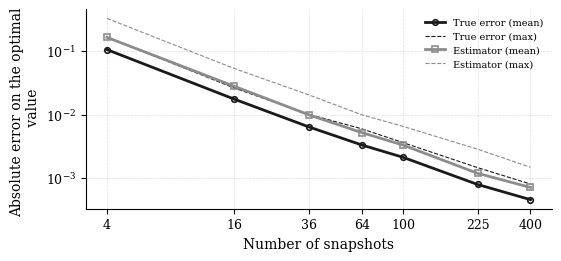

Estimator >= true error everywhere: True


In [35]:
# Comparison of the true RB error and the error estimator, w.r.t. the number of snapshots

true_err = np.abs(RB_val_all - LP_val)     # |W_RB - W_LP|, shape (len(nb_snap_tab), size_A_test)
est_err = RB_val_all - RB_est_all          # computable bound: W_RB - max_p <phi_p, mu> + <psi_p, nu>

plt.close("all")
fig, ax = plt.subplots(figsize=(5.5, 2.5), constrained_layout=True)

x = np.array(nb_snap_tab)**2   # number of snapshots

# True error: mean (solid) and max (dashed)
ax.plot(x, true_err.mean(axis=1), color="0.1", lw=2, marker="o", ms=4, mfc="none", mew=1.2, label="True error (mean)")
ax.plot(x, true_err.max(axis=1), color="0.1", lw=0.8, ls="--", label="True error (max)")

# Estimated error: mean (solid) and max (dashed)
ax.plot(x, est_err.mean(axis=1), color="0.55", lw=2, marker="s", ms=4, mfc="none", mew=1.2, label="Estimator (mean)")
ax.plot(x, est_err.max(axis=1), color="0.55", lw=0.8, ls="--", label="Estimator (max)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.minorticks_off()
ax.set_xlabel("Number of snapshots")
ax.set_ylabel("Absolute error on the optimal \n value")

ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=7)

fig.savefig(os.path.join(fig_dir, "RB_error_estimation.pdf"), bbox_inches="tight")
plt.show()

# Sanity check: the estimator must bound the true error at every test point
print("Estimator >= true error everywhere:", np.all(est_err >= true_err - 1e-10))

In [39]:
effectivity = est_err / true_err
print("Mean effectivity:", dict(zip(x, effectivity.mean(axis=1).round(2))))

Mean effectivity: {np.int64(4): np.float64(1.44), np.int64(16): np.float64(1.5), np.int64(36): np.float64(1.48), np.int64(64): np.float64(1.48), np.int64(100): np.float64(1.5), np.int64(225): np.float64(1.42), np.int64(400): np.float64(1.48)}


## Using the Error estimator to build a nice grid 

In [50]:
# Greedy construction of the reduced basis on a grid, driven by the error estimator (RB solved with LP)
# Records the HF cost (time_G) and the search cost (time_search) of every snapshot, for the break-even point

n_grid = 50                           # grid of n_grid x n_grid parameters
P_max = 400                           # maximum number of snapshots (raise it to continue: the run resumes)
tol = 1e-10                           # stop if the max estimated error on the grid is below tol

a_lin = np.linspace(0, 1, n_grid)
A_grid = np.array(np.meshgrid(a_lin, a_lin)).reshape(2, -1)   # shape (2, n_grid**2), contains the 4 corners


def hf_snapshot(a_mu, a_nu):
    """Primal LP (value + plan) and dual LP (potentials) at one parameter."""
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
    munu = np.concatenate([mu, nu])
    res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=munu, bounds=(None, None), method='highs-ds', options=options)
    res_d = opt.linprog(-munu, A_ub=A.T, b_ub=c, bounds=(None, None), method='highs-ds', options=options)
    if not (res.success and res_d.success):
        print(f"Warning: LP failed at alpha = ({a_mu:.3f}, {a_nu:.3f})")
    return res.fun, res.x, res_d.x[:Nx], res_d.x[Nx:]


# --- Initialisation with the 4 corners (or resume from disk) ---
filename = os.path.join(save_dir, f"greedy_LP_grid{n_grid}_timed.npz")
if os.path.exists(filename):
    data = np.load(filename)
    A_G, Wc_G = list(data["A_G"].T), list(data["Wc_G"])
    P_HF_G, phi_G, psi_G = list(data["P_HF_G"].T), list(data["phi_G"]), list(data["psi_G"])
    est_max_hist, time_G, time_search = list(data["est_max_hist"]), list(data["time_G"]), list(data["time_search"])
    print(f"Greedy basis loaded from {filename}: {len(Wc_G)} snapshots")
else:
    A_G, Wc_G, P_HF_G, phi_G, psi_G, est_max_hist, time_G, time_search = [], [], [], [], [], [], [], []
    for a_mu, a_nu in [(0, 0), (0, 1), (1, 0), (1, 1)]:
        t_start = perf_counter()
        W, plan, phi, psi = hf_snapshot(a_mu, a_nu)
        time_G.append(perf_counter() - t_start)
        time_search.append(0.)                        # corners: no search
        A_G.append(np.array([a_mu, a_nu])); Wc_G.append(W); P_HF_G.append(plan); phi_G.append(phi); psi_G.append(psi)


def save_greedy():
    np.savez(filename, A_G=np.array(A_G).T, Wc_G=np.array(Wc_G), P_HF_G=np.array(P_HF_G).T,
             phi_G=np.array(phi_G), psi_G=np.array(psi_G), est_max_hist=np.array(est_max_hist),
             time_G=np.array(time_G), time_search=np.array(time_search))


# --- Greedy loop ---
while len(Wc_G) < P_max:
    t_iter = perf_counter()
    P = len(Wc_G)
    K_G = np.vstack([np.array(A_G).T, np.ones(P)])
    W_arr, A_ub_G, b_ub_G = np.array(Wc_G), -np.eye(P), np.zeros(P)
    phi_arr, psi_arr = np.array(phi_G), np.array(psi_G)

    # Estimated error at every grid point: RB value (LP) - best dual value among the snapshots
    est = np.zeros(A_grid.shape[1])
    for i, (a_mu, a_nu) in enumerate(A_grid.T):
        res = opt.linprog(W_arr, A_ub=A_ub_G, b_ub=b_ub_G, A_eq=K_G, b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
        est[i] = res.fun - (phi_arr @ mu + psi_arr @ nu).max()

    i_worst = np.argmax(est)
    est_max_hist.append(est[i_worst])
    if est[i_worst] < tol:
        print(f"Converged: max estimated error {est[i_worst]:.2e} < tol")
        break
    t_search_iter = perf_counter() - t_iter

    # Add the worst point to the basis
    a_mu, a_nu = A_grid[:, i_worst]
    t_start = perf_counter()
    W, plan, phi, psi = hf_snapshot(a_mu, a_nu)
    time_G.append(perf_counter() - t_start)
    time_search.append(t_search_iter)
    A_G.append(np.array([a_mu, a_nu])); Wc_G.append(W); P_HF_G.append(plan); phi_G.append(phi); psi_G.append(psi)
    print(f"P = {len(Wc_G):4d} | max est. error before adding = {est[i_worst]:.2e} | "
          f"new point ({a_mu:.3f}, {a_nu:.3f}) | search {t_search_iter:.1f} s | HF {time_G[-1]:.1f} s")

    if len(Wc_G) % 10 == 0:
        save_greedy()

save_greedy()
A_G, Wc_G, P_HF_G = np.array(A_G).T, np.array(Wc_G), np.array(P_HF_G).T   # arrays for the next cells
time_G, time_search = np.array(time_G), np.array(time_search)
print(f"Greedy basis: {len(Wc_G)} snapshots | offline time: HF {time_G.sum():.1f} s + search {time_search.sum():.1f} s")

Greedy basis loaded from saved_snapshots/greedy_LP_grid50_timed.npz: 400 snapshots
Greedy basis: 400 snapshots | offline time: HF 443.5 s + search 1916.1 s


In [51]:
# True error of the greedy RB model on the test set, for several basis sizes

P_eval = [P for P in [4, 9, 16, 25, 36, 50, 75, 100, 150, 200, 300, 400] if P <= len(Wc_G)]
nb_snap_tab = [2, 4, 6, 8, 10, 15, 20]
G_err_mean, G_err_max = np.zeros(len(P_eval)), np.zeros(len(P_eval))
G_L2_mean, G_L2_max = np.zeros(len(P_eval)), np.zeros(len(P_eval))

for i, P in enumerate(P_eval):
    K_G = np.vstack([A_G[:, :P], np.ones(P)])          # first P greedy snapshots
    A_ub_G, b_ub_G = -np.eye(P), np.zeros(P)

    G_val, G_L2 = np.zeros(size_A_test), np.zeros(size_A_test)
    for k, (a_mu, a_nu) in enumerate(A_test):
        res = opt.linprog(Wc_G[:P], A_ub=A_ub_G, b_ub=b_ub_G, A_eq=K_G, b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        G_val[k] = res.fun
        G_L2[k] = np.linalg.norm(P_HF_G[:, :P] @ res.x - LP_plan[:, k]) / np.linalg.norm(LP_plan[:, k])

    err = np.abs(LP_val - G_val)
    G_err_mean[i], G_err_max[i] = err.mean(), err.max()
    G_L2_mean[i], G_L2_max[i] = G_L2.mean(), G_L2.max()

np.savez(os.path.join(save_dir, f"greedy_test_{size_A_test}.npz"), P_eval=P_eval,
         G_err_mean=G_err_mean, G_err_max=G_err_max, G_L2_mean=G_L2_mean, G_L2_max=G_L2_max)

In [52]:
# Break-even point of the greedy RB model: T_off + N * t_RB = N * t_LP
# (needs LP_time, LP_val, LP_plan, A_test from the HF test cell, and A_G, Wc_G, P_HF_G, time_G, time_search from the greedy cell)

ERR = 'value'                                 # 'L2': relative L2 error on the plan, 'value': error on the optimal value
OFFLINE = 'HF+search'                         # 'HF': snapshot cost only, 'HF+search': snapshots + greedy search

t_LP = LP_time.mean()                         # mean HF (LP) solving time on the test set
P_eval = [P for P in [4, 9, 16, 25, 36, 50, 75, 100, 150, 200, 300, 400] if P <= len(Wc_G)]
nP = len(P_eval)

G_err_mean, G_err_max = np.zeros(nP), np.zeros(nP)
G_L2_mean, G_L2_max = np.zeros(nP), np.zeros(nP)
G_time_mean, G_time_gain_mean = np.zeros(nP), np.zeros(nP)
G_T_HF, G_T_search = np.zeros(nP), np.zeros(nP)

for i, P in enumerate(P_eval):
    K_G, A_ub_G, b_ub_G = np.vstack([A_G[:, :P], np.ones(P)]), -np.eye(P), np.zeros(P)
    G_val, G_L2, G_t = np.zeros(size_A_test), np.zeros(size_A_test), np.zeros(size_A_test)
    for k, (a_mu, a_nu) in enumerate(A_test):
        t_start = perf_counter()
        res = opt.linprog(Wc_G[:P], A_ub=A_ub_G, b_ub=b_ub_G, A_eq=K_G, b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        G_t[k] = perf_counter() - t_start
        G_val[k] = res.fun
        G_L2[k] = np.linalg.norm(P_HF_G[:, :P] @ res.x - LP_plan[:, k]) / np.linalg.norm(LP_plan[:, k])

    err = np.abs(LP_val - G_val)
    G_err_mean[i], G_err_max[i] = err.mean(), err.max()
    G_L2_mean[i], G_L2_max[i] = G_L2.mean(), G_L2.max()
    G_time_mean[i] = G_t.mean()
    G_time_gain_mean[i] = (LP_time / G_t).mean()
    G_T_HF[i], G_T_search[i] = time_G[:P].sum(), time_search[:P].sum()

np.savez(os.path.join(save_dir, f"greedy_test_{size_A_test}.npz"), P_eval=P_eval,
         G_err_mean=G_err_mean, G_err_max=G_err_max, G_L2_mean=G_L2_mean, G_L2_max=G_L2_max,
         G_time_mean=G_time_mean, G_time_gain_mean=G_time_gain_mean, G_T_HF=G_T_HF, G_T_search=G_T_search)

# Break-even number of queries
err_mean, err_max = (G_L2_mean, G_L2_max) if ERR == 'L2' else (G_err_mean, G_err_max)
T_off = G_T_HF + G_T_search if OFFLINE == 'HF+search' else G_T_HF

N_star = np.full(nP, np.inf)
for i in range(nP):
    if G_time_mean[i] < t_LP:                 # otherwise RB never pays back
        N_star[i] = np.ceil(T_off[i] / (t_LP - G_time_mean[i]))

# Readable table
print(f"Mean LP time: {t_LP:.3e} s   (errors: {ERR}, offline: {OFFLINE})\n")
print(f"{'Snapshots':>10} | {'Offline (s)':>12} | {'Online (s)':>10} | {'break-even N*':>8} | {'Time gain':>10} | {'Mean err':>10} | {'Max err':>10}")
print("-" * 88)
for n, T, t, N, g, em, eM in zip(P_eval, T_off, G_time_mean, N_star, G_time_gain_mean, err_mean, err_max):
    print(f"{n:>10} | {T:>12.2f} | {t:>10.2e} | {N:>8.0f} | {g:>10.0f} | {em:>10.2e} | {eM:>10.2e}")

# LaTeX rows, ready to paste into the table
print("\n% LaTeX rows")
for n, T, t, N, g, em, eM in zip(P_eval, T_off, G_time_mean, N_star, G_time_gain_mean, err_mean, err_max):
    print(f"{n} & {T:.2f} & {t:.2e} & {N:.0f} & {g:.0f} & {em:.2e} & {eM:.2e} \\\\")

Mean LP time: 1.016e+00 s   (errors: value, offline: HF+search)

 Snapshots |  Offline (s) | Online (s) | break-even N* |  Time gain |   Mean err |    Max err
----------------------------------------------------------------------------------------
         4 |         4.19 |   7.94e-04 |        5 |       1317 |   1.15e-01 |   1.67e-01
         9 |        20.99 |   8.80e-04 |       21 |       1159 |   3.23e-02 |   6.92e-02
        16 |        45.60 |   9.01e-04 |       45 |       1129 |   1.50e-02 |   3.23e-02
        25 |        78.83 |   9.55e-04 |       78 |       1064 |   8.65e-03 |   1.80e-02
        36 |       120.06 |   1.01e-03 |      119 |       1011 |   5.21e-03 |   1.03e-02
        50 |       173.77 |   1.49e-03 |      172 |        684 |   3.44e-03 |   7.75e-03
        75 |       274.84 |   1.87e-03 |      271 |        542 |   2.23e-03 |   4.55e-03
       100 |       382.67 |   2.23e-03 |      378 |        455 |   1.65e-03 |   4.16e-03
       150 |       620.71 |   2.79e-03 |

In [103]:
# Break-even point of the greedy RB model, compared with the regular grid
# (needs LP_time, LP_val, A_test from the HF test cell, and time_tab, RB_time_mean, RB_err_mean from the regular RB cells)

t_LP = LP_time.mean()
P_eval = [P for P in [4, 9, 16, 25, 36, 50, 75, 100, 150, 200, 300, 400] if P <= len(Wc_G)]

G_err_mean, G_time_mean, G_T_off = np.zeros(len(P_eval)), np.zeros(len(P_eval)), np.zeros(len(P_eval))
for i, P in enumerate(P_eval):
    K_G, A_ub_G, b_ub_G = np.vstack([A_G[:, :P], np.ones(P)]), -np.eye(P), np.zeros(P)
    G_val, G_t = np.zeros(size_A_test), np.zeros(size_A_test)
    for k, (a_mu, a_nu) in enumerate(A_test):
        t_start = perf_counter()
        res = opt.linprog(Wc_G[:P], A_ub=A_ub_G, b_ub=b_ub_G, A_eq=K_G, b_eq=np.array([a_mu, a_nu, 1.]),
                          bounds=(None, None), method='highs-ds', options=options)
        G_t[k] = perf_counter() - t_start
        G_val[k] = res.fun
    G_err_mean[i], G_time_mean[i] = np.abs(LP_val - G_val).mean(), G_t.mean()
    G_T_off[i] = time_G[:P].sum() + time_search[:P].sum()

table_greedy = pd.DataFrame({
    "Snapshots": P_eval,
    "Mean error": G_err_mean,
    "Offline: HF (s)": [time_G[:P].sum() for P in P_eval],
    "Offline: search (s)": [time_search[:P].sum() for P in P_eval],
    "t_RB (s)": G_time_mean,
    "N* (HF only)": [break_even(time_G[:P].sum(), t_LP, t) for P, t in zip(P_eval, G_time_mean)],
    "N* (HF + search)": [break_even(T, t_LP, t) for T, t in zip(G_T_off, G_time_mean)],
}).set_index("Snapshots")

table_regular = pd.DataFrame({
    "Snapshots": np.array(nb_snap_tab)**2,
    "Mean error": RB_err_mean,
    "Offline (s)": time_tab,
    "t_RB (s)": RB_time_mean,
    "N*": [break_even(T, t_LP, t) for T, t in zip(time_tab, RB_time_mean)],
}).set_index("Snapshots")

print(f"Mean LP time: {t_LP:.3e} s")
display(table_regular)
display(table_greedy)

Mean LP time: 9.933e-01 s


,Mean error,Offline (s),t_RB (s),N*
Snapshots,,,,
4,0.105701,4.031109,0.000785,5.0
16,0.017484,16.245317,0.000942,17.0
36,0.006391,36.540115,0.000963,37.0
64,0.003320,65.171507,0.001399,66.0
100,0.002126,101.056601,0.001718,102.0
225,0.000794,227.971929,0.002922,231.0
400,0.000457,404.025672,0.005125,409.0


,Mean error,Offline: HF (s),Offline: search (s),t_RB (s),N* (HF only),N* (HF + search)
Snapshots,,,,,,
4,0.179557,4.185402,0.000000,0.000815,5.0,5.0
9,0.150772,9.692618,11.297860,0.000913,10.0,22.0
16,0.150186,17.346869,28.251621,0.000915,18.0,46.0
25,0.149183,27.485446,51.347013,0.000974,28.0,80.0
36,0.149748,39.574796,80.482309,0.001014,40.0,121.0
50,0.149590,55.133620,118.640522,0.001077,56.0,176.0
75,0.149698,82.936271,191.908317,0.001167,84.0,278.0
100,0.149659,110.444621,272.224448,0.001342,112.0,386.0
150,0.149625,166.246975,454.458475,0.001508,168.0,626.0


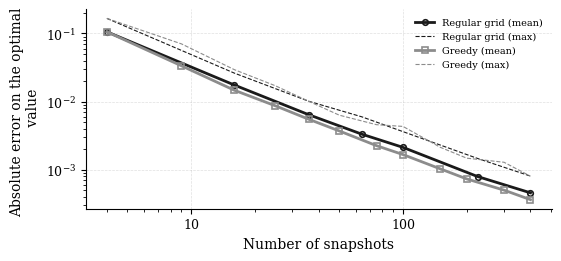

In [91]:
# Mean error vs number of snapshots: regular grid vs greedy selection

plt.close("all")
fig, ax = plt.subplots(figsize=(5.5, 2.5), constrained_layout=True)

x_reg = np.array(nb_snap_tab)**2

ax.plot(x_reg, RB_err_mean, color="0.1", lw=2, marker="o", ms=4, mfc="none", mew=1.2, label="Regular grid (mean)")
ax.plot(x_reg, RB_err_max, color="0.1", lw=0.8, ls="--", label="Regular grid (max)")
ax.plot(P_eval, G_err_mean, color="0.55", lw=2, marker="s", ms=4, mfc="none", mew=1.2, label="Greedy (mean)")
ax.plot(P_eval, G_err_max, color="0.55", lw=0.8, ls="--", label="Greedy (max)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())   # 10, 100 instead of 10^1, 10^2
ax.set_xlabel("Number of snapshots")
ax.set_ylabel("Absolute error on the optimal \n value")
ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=7)

fig.savefig(os.path.join(fig_dir, "RB_regular_vs_greedy.pdf"), bbox_inches="tight")
plt.show()

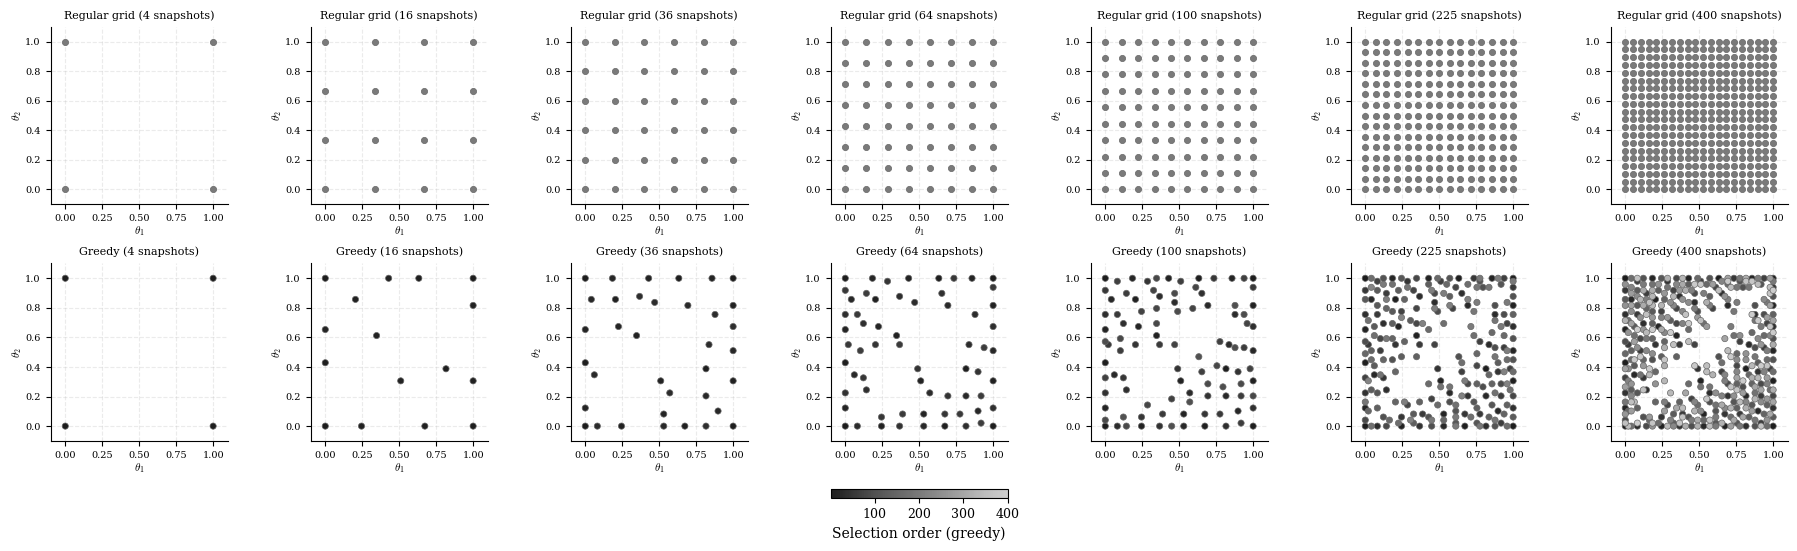

In [48]:
# Snapshot locations in the parameter plane: regular grid vs greedy selection

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=256):
    return mcolors.LinearSegmentedColormap.from_list(f"{cmap.name}_trunc", cmap(np.linspace(minval, maxval, n)))

if isinstance(A_G, list):   # greedy cell interrupted before its final conversion
    A_G, Wc_G, P_HF_G = np.array(A_G).T, np.array(Wc_G), np.array(P_HF_G).T

P_common = [n**2 for n in nb_snap_tab if n**2 <= A_G.shape[1]]   # basis sizes available for both methods
P_ref = P_common[-1]                                              # common colour scale for the greedy points

plt.close("all")
fig, axes = plt.subplots(2, len(P_common), figsize=(2.6 * len(P_common), 5.4), constrained_layout=True, squeeze=False)

for j, P in enumerate(P_common):
    A_reg = bases[int(np.sqrt(P))]["K"][:2]
    A_greedy = A_G[:, :P]

    # Regular grid
    axes[0, j].scatter(A_reg[0], A_reg[1], color=plt.cm.Greys(0.6), s=20, edgecolors="0.4", linewidths=0.5, zorder=2)
    axes[0, j].set_title(f"Regular grid ({P} snapshots)", fontsize=8)

    # Greedy: grey level = selection index, same scale on every panel (dark = selected early)
    order = np.arange(P) / max(P_ref - 1, 1)
    axes[1, j].scatter(A_greedy[0], A_greedy[1], color=plt.cm.Greys(0.9 - 0.6 * order), s=20,
                       edgecolors="0.4", linewidths=0.5, zorder=2)
    axes[1, j].set_title(f"Greedy ({P} snapshots)", fontsize=8)

for ax in axes.flat:
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.set_xlabel(r"$\theta_1$", fontsize=8, labelpad=1)
    ax.set_ylabel(r"$\theta_2$", fontsize=8, labelpad=1)
    ax.tick_params(labelsize=7)

# Colorbar for the selection order (same grey range as 0.9 - 0.6 * order)
cmap_order = truncate_colormap(plt.cm.Greys_r, 0.1, 0.7)
norm_order = mcolors.Normalize(vmin=1, vmax=P_ref)
fig.colorbar(mpl.cm.ScalarMappable(norm=norm_order, cmap=cmap_order), ax=axes[1, :], orientation="horizontal",
             fraction=0.05, pad=0.08, label="Selection order (greedy)")

fig.savefig(os.path.join(fig_dir, f"snapshots_regular_vs_greedy_grid{n_grid}.pdf"), bbox_inches="tight")
plt.show()

# 1D case

## Preliminaries

In [49]:
# Section: one parameter (Kx = 1, Ky = 2): mu = mu0 fixed, nu(alpha) = alpha*nu0 + (1-alpha)*nu1
# Requires the setup cell re-run with Nx = Ny = 100

save_dir_1p = "saved_1param"
fig_dir = "figures"
os.makedirs(save_dir_1p, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

options = {'dual_feasibility_tolerance': 1e-10, 'primal_feasibility_tolerance': 1e-10}
n_alpha = 201                                 # parameter grid for the curves
alpha_grid = np.linspace(0, 1, n_alpha)


def nu_of(alpha):
    return alpha*nu0 + (1-alpha)*nu1


def hf_primal(alpha):
    """HF optimal value and transport plan at alpha."""
    res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=np.concatenate([mu0, nu_of(alpha)]),
                      bounds=(None, None), method='highs-ds', options=options)
    if not res.success:
        print(f"Warning: primal LP failed at alpha = {alpha:.3f}: {res.message}")
    return res.fun, res.x


def hf_dual(alpha):
    """HF dual potentials (phi, psi) at alpha."""
    res = opt.linprog(-np.concatenate([mu0, nu_of(alpha)]), A_ub=A.T, b_ub=c,
                      bounds=(None, None), method='highs-ds', options=options)
    if not res.success:
        print(f"Warning: dual LP failed at alpha = {alpha:.3f}: {res.message}")
    return res.x[:Nx], res.x[Nx:]


def rb_solve_1p(a_snap, W_snap, alpha):
    """RB optimal value at alpha from snapshots at a_snap with values W_snap."""
    P = len(a_snap)
    res = opt.linprog(W_snap, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=np.vstack([a_snap, np.ones(P)]),
                      b_eq=np.array([alpha, 1.]), bounds=(None, None), method='highs-ds', options=options)
    return res.fun


def cached(filename, compute):
    """Load the arrays saved in filename, or compute them (dict of arrays) and save them."""
    path = os.path.join(save_dir_1p, filename)
    if os.path.exists(path):
        print(f"Loaded {path}")
        return dict(np.load(path))
    out = compute()
    np.savez(path, **out)
    print(f"Computed and saved {path}")
    return out


def style_ax(ax):
    ax.set_xlabel(r"$\alpha$")
    ax.grid(True, ls="--", lw=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=7)

## Graphs $I(\alpha)$, $I_{RB}(\alpha)$, and lower estimation

In [50]:
# HF value I(alpha) on the parameter grid

def compute_I():
    I_val = np.zeros(n_alpha)
    t_start = perf_counter()
    for i, a in enumerate(alpha_grid):
        I_val[i], _ = hf_primal(a)
    return {"I_val": I_val, "time": perf_counter() - t_start}

I_val = cached(f"I_hf_N{Nx}_na{n_alpha}.npz", compute_I)["I_val"]

Computed and saved saved_1param/I_hf_N100_na201.npz


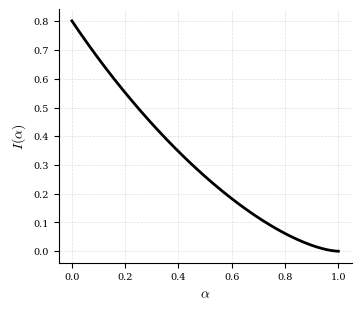

In [65]:
# Plot of the HF value I(alpha)

plt.close("all")
fig, ax = plt.subplots(figsize=(3.5, 3), constrained_layout=True)
ax.plot(alpha_grid, I_val, color="k", lw=2)
ax.set_ylabel(r"$I(\alpha)$")
style_ax(ax)
fig.savefig(os.path.join(fig_dir, "1p_I_hf.pdf"), bbox_inches="tight")
plt.show()

In [66]:
# Reduced models: snapshots on a regular grid of P points in [0, 1]

P_tab_1p = [2,3, 4, 10, 20]
rb_1p = {}

for P in P_tab_1p:
    def compute(P=P):
        a_snap = np.linspace(0, 1, P)
        W_snap, plans = np.zeros(P), np.zeros((Nx*Ny, P))
        t_start = perf_counter()
        for p, a in enumerate(a_snap):
            W_snap[p], plans[:, p] = hf_primal(a)
        return {"a_snap": a_snap, "W_snap": W_snap, "plans": plans, "time": perf_counter() - t_start}
    rb_1p[P] = cached(f"rb_snap_P{P}_N{Nx}.npz", compute)

Loaded saved_1param/rb_snap_P2_N100.npz
Computed and saved saved_1param/rb_snap_P3_N100.npz
Loaded saved_1param/rb_snap_P4_N100.npz
Loaded saved_1param/rb_snap_P10_N100.npz
Loaded saved_1param/rb_snap_P20_N100.npz


In [67]:
# RB value I_RB(alpha) on the parameter grid, for each model

I_RB_1p = {P: np.array([rb_solve_1p(rb_1p[P]["a_snap"], rb_1p[P]["W_snap"], a) for a in alpha_grid])
           for P in P_tab_1p}

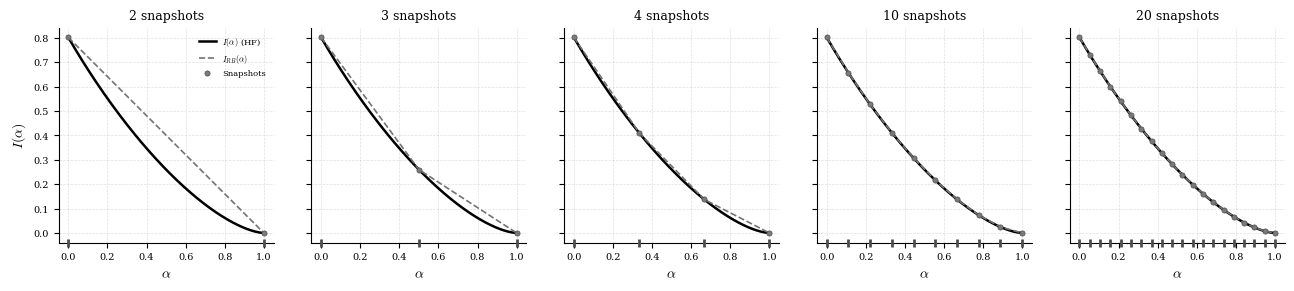

In [70]:
# I(alpha) and the RB approximations, one panel per model

plt.close("all")
fig, axes = plt.subplots(1, len(P_tab_1p), figsize=(2.6 * len(P_tab_1p), 2.8), constrained_layout=True, sharey=True)

for ax, P in zip(axes, P_tab_1p):
    a_snap, W_snap = rb_1p[P]["a_snap"], rb_1p[P]["W_snap"]
    ax.plot(alpha_grid, I_val, color="k", lw=1.8, label=r"$I(\alpha)$ (HF)")
    ax.plot(alpha_grid, I_RB_1p[P], color="0.45", lw=1.2, ls="--", label=r"$I_{RB}(\alpha)$")

    # Snapshots: on the curve and on the alpha axis
    ax.scatter(a_snap, W_snap, color=plt.cm.Greys(0.6), s=14, edgecolors="0.3", linewidths=0.5, zorder=3,
               label="Snapshots")
    ax.scatter(a_snap, np.zeros(P), transform=ax.get_xaxis_transform(), marker="|", s=40, color="0.3",
               clip_on=False, zorder=3)

    ax.set_title(f"{P} snapshots", fontsize=9)
    ax.set_box_aspect(1)
    style_ax(ax)

axes[0].set_ylabel(r"$I(\alpha)$")
axes[0].legend(frameon=False, fontsize=6)
fig.savefig(os.path.join(fig_dir, "1p_I_rb.pdf"), bbox_inches="tight")
plt.show()

In [71]:
# Dual potentials at the snapshots of each RB model

def lower_bound_1p(phi, psi, alphas=alpha_grid):
    """max_p <phi_p, mu0> + <psi_p, nu(alpha)>: max of the tangent lines at the snapshots."""
    D0 = phi @ mu0 + psi @ nu1          # value at alpha = 0
    D1 = psi @ (nu0 - nu1)              # slope in alpha
    return (D0[:, None] + D1[:, None] * alphas).max(axis=0)

for P in P_tab_1p:
    def compute(P=P):
        phi, psi = np.zeros((P, Nx)), np.zeros((P, Ny))
        t_start = perf_counter()
        for p, a in enumerate(rb_1p[P]["a_snap"]):
            phi[p], psi[p] = hf_dual(a)
        return {"phi": phi, "psi": psi, "time_dual": perf_counter() - t_start}
    rb_1p[P].update(cached(f"rb_dual_P{P}_N{Nx}.npz", compute))

Loaded saved_1param/rb_dual_P2_N100.npz
Computed and saved saved_1param/rb_dual_P3_N100.npz
Loaded saved_1param/rb_dual_P4_N100.npz
Loaded saved_1param/rb_dual_P10_N100.npz
Loaded saved_1param/rb_dual_P20_N100.npz


In [72]:
# Lower bound on the parameter grid, for each model

lower_1p = {P: lower_bound_1p(rb_1p[P]["phi"], rb_1p[P]["psi"]) for P in P_tab_1p}

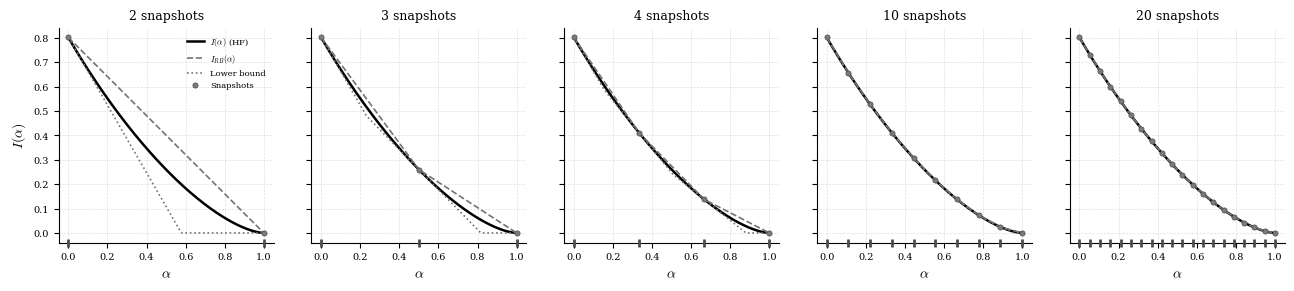

In [73]:
# I(alpha), RB value and lower bound, one panel per model

def plot_rb_panels(panels, filename, ncols):
    """panels: list of (title, a_snap, W_snap, I_rb, lower)."""
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.8 * nrows), constrained_layout=True,
                             sharey=True, squeeze=False)
    for ax, (title, a_snap, W_snap, I_rb, lower) in zip(axes.flat, panels):
        ax.plot(alpha_grid, I_val, color="k", lw=1.8, label=r"$I(\alpha)$ (HF)")
        ax.plot(alpha_grid, I_rb, color="0.45", lw=1.2, ls="--", label=r"$I_{RB}(\alpha)$")
        ax.plot(alpha_grid, lower, color="0.45", lw=1.2, ls=":", label="Lower bound")

        # Snapshots: on the curve and on the alpha axis
        ax.scatter(a_snap, W_snap, color=plt.cm.Greys(0.6), s=14, edgecolors="0.3", linewidths=0.5, zorder=3,
                   label="Snapshots")
        ax.scatter(a_snap, np.zeros(len(a_snap)), transform=ax.get_xaxis_transform(), marker="|", s=40,
                   color="0.3", clip_on=False, zorder=3)

        ax.set_title(title, fontsize=9)
        ax.set_box_aspect(1)
        style_ax(ax)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel(r"$I(\alpha)$")
    axes[0, 0].legend(frameon=False, fontsize=6)
    fig.savefig(os.path.join(fig_dir, filename), bbox_inches="tight")
    plt.show()

plt.close("all")
plot_rb_panels([(f"{P} snapshots", rb_1p[P]["a_snap"], rb_1p[P]["W_snap"], I_RB_1p[P], lower_1p[P])
                for P in P_tab_1p], "1p_I_rb_lower.pdf", ncols=5)

## Grid adaptation

In [74]:
# Greedy construction: start from alpha = 0 and 1, add the parameter where the estimated error is worst

P_max_G1 = 20
tol_G1 = 1e-10
path = os.path.join(save_dir_1p, f"greedy_1p_N{Nx}_na{n_alpha}.npz")

if os.path.exists(path):
    d = np.load(path)
    a_G1, W_G1 = list(d["a_G1"]), list(d["W_G1"])
    phi_G1, psi_G1, est_hist_G1 = list(d["phi_G1"]), list(d["psi_G1"]), list(d["est_hist_G1"])
    print(f"Greedy basis loaded from {path}: {len(a_G1)} snapshots")
else:
    a_G1, W_G1, phi_G1, psi_G1, est_hist_G1 = [], [], [], [], []
    for a in [0., 1.]:
        W, _ = hf_primal(a)
        phi, psi = hf_dual(a)
        a_G1.append(a); W_G1.append(W); phi_G1.append(phi); psi_G1.append(psi)

while len(a_G1) < P_max_G1:
    a_arr, W_arr = np.array(a_G1), np.array(W_G1)
    I_rb = np.array([rb_solve_1p(a_arr, W_arr, a) for a in alpha_grid])
    est = I_rb - lower_bound_1p(np.array(phi_G1), np.array(psi_G1))

    i_worst = np.argmax(est)
    est_hist_G1.append(est[i_worst])
    if est[i_worst] < tol_G1:
        print(f"Converged: max estimated error {est[i_worst]:.2e} < tol")
        break

    a_new = alpha_grid[i_worst]
    W, _ = hf_primal(a_new)
    phi, psi = hf_dual(a_new)
    a_G1.append(a_new); W_G1.append(W); phi_G1.append(phi); psi_G1.append(psi)
    print(f"P = {len(a_G1):3d} | max est. error before adding = {est[i_worst]:.2e} | new point alpha = {a_new:.3f}")

np.savez(path, a_G1=np.array(a_G1), W_G1=np.array(W_G1), phi_G1=np.array(phi_G1), psi_G1=np.array(psi_G1),
         est_hist_G1=np.array(est_hist_G1))

Greedy basis loaded from saved_1param/greedy_1p_N100_na201.npz: 20 snapshots


In [75]:
# RB value and lower bound of the greedy models after 2, 4, 6, 10, 15, 20 snapshots

steps_G1 = [s for s in [2, 4, 6, 10, 15, 20] if s <= len(a_G1)]
a_G1_arr, W_G1_arr, phi_G1_arr, psi_G1_arr = map(np.array, (a_G1, W_G1, phi_G1, psi_G1))

I_RB_G1 = {s: np.array([rb_solve_1p(a_G1_arr[:s], W_G1_arr[:s], a) for a in alpha_grid]) for s in steps_G1}
lower_G1 = {s: lower_bound_1p(phi_G1_arr[:s], psi_G1_arr[:s]) for s in steps_G1}

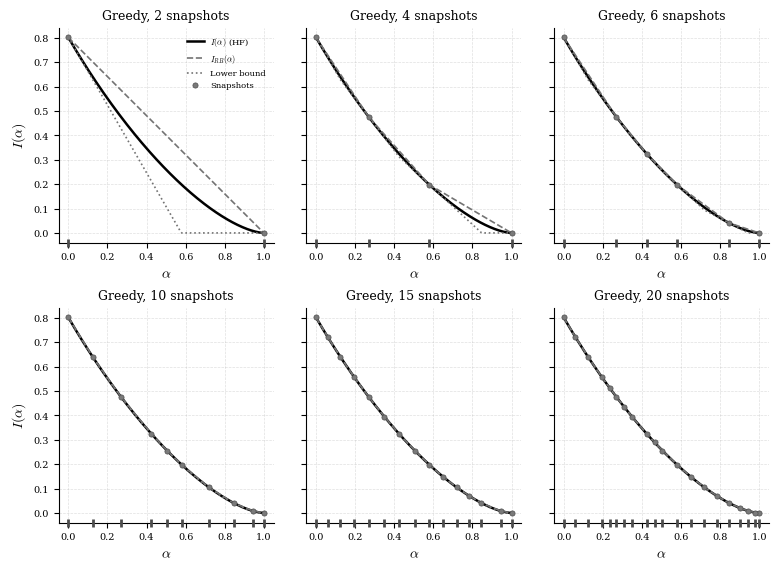

In [76]:
# Greedy models: I(alpha), RB value, lower bound and selected snapshots

plt.close("all")
plot_rb_panels([(f"Greedy, {s} snapshots", a_G1_arr[:s], W_G1_arr[:s], I_RB_G1[s], lower_G1[s])
                for s in steps_G1], "1p_greedy.pdf", ncols=3)

# Analysis of the behaviour when Kx + Ky vary

## set up

In [53]:
# Section: Kx varies (Kx bumps with evenly spaced centres), nu fixed (Ky = 1)
# Requires the setup cell with Nx = Ny = 100 (X, nu0, c, A, Apos, bpos)

import itertools
from math import comb
from scipy.spatial import cKDTree
import pandas as pd

save_dir_K = "saved_Kx"
os.makedirs(save_dir_K, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
options = {'dual_feasibility_tolerance': 1e-10, 'primal_feasibility_tolerance': 1e-10}

Kx_tab = [2, 3, 4, 5, 6]
size_test_K = 100
seed_K = 0
nu_fix = nu0
sigma_K = 0.5                                  # same width as your original bumps


def make_marginals(Kx):
    """Kx bumps built like mu0, mu1 (same sigma), centres evenly spaced in [-Le/2, Le/2], normalised to mass 1."""
    centres = np.linspace(-Le/2, Le/2, Kx)
    mus = np.exp(-(X[None, :] - centres[:, None])**2 / sigma_K**2)
    return mus / mus.sum(axis=1, keepdims=True)

marginals = {Kx: make_marginals(Kx) for Kx in Kx_tab}


def hf_primal_K(lam, mus):
    """HF optimal value for mu = sum_k lam_k mu_k."""
    res = opt.linprog(c, A_ub=-Apos, b_ub=bpos, A_eq=A, b_eq=np.concatenate([lam @ mus, nu_fix]),
                      bounds=(None, None), method='highs-ds', options=options)
    if not res.success:
        print(f"Warning: primal LP failed at lambda = {np.round(lam, 3)}: {res.message}")
    return res.fun


def hf_dual_K(lam, mus):
    """HF dual potentials (phi, psi) for mu = sum_k lam_k mu_k."""
    res = opt.linprog(-np.concatenate([lam @ mus, nu_fix]), A_ub=A.T, b_ub=c,
                      bounds=(None, None), method='highs-ds', options=options)
    if not res.success:
        print(f"Warning: dual LP failed at lambda = {np.round(lam, 3)}: {res.message}")
    return res.x[:Nx], res.x[Nx:]


def make_K(Lam_snap):
    """Reduced constraint matrix: first Kx-1 barycentric coordinates + row of ones."""
    return np.vstack([Lam_snap[:-1], np.ones(Lam_snap.shape[1])])


def rb_solve_K(K, W_snap, lam):
    """RB optimal value at lam."""
    res = opt.linprog(W_snap, A_eq=K, b_eq=np.append(lam[:-1], 1.), bounds=(0, None),
                      method='highs-ds', options=options)
    return res.fun


def lower_bound_K(phi, psi, mus, Lam):
    """max_p <phi_p, mu(lam)> + <psi_p, nu> for every column lam of Lam."""
    return (phi @ mus.T @ Lam + (psi @ nu_fix)[:, None]).max(axis=0)


def simplex_grid(Kx, m):
    """Regular grid of the simplex with step 1/m, shape (Kx, comb(m+Kx-1, Kx-1))."""
    pts = np.array([comp for comp in itertools.product(range(m + 1), repeat=Kx - 1) if sum(comp) <= m]) / m
    return np.vstack([pts.T, 1 - pts.sum(axis=1)])


def fill_distance(Lam_snap, Kx, n=20000):
    """Estimated fill distance: max over n random points of the simplex of the distance to the nearest snapshot."""
    pts = np.random.default_rng(1).dirichlet(np.ones(Kx), n)
    return cKDTree(Lam_snap.T).query(pts)[0].max()


def break_even(T_off, t_LP, t_RB):
    return np.ceil(T_off / (t_LP - t_RB)) if t_RB < t_LP else np.inf


def cached_K(filename, compute):
    """Load the arrays saved in filename, or compute them (dict of arrays) and save them."""
    path = os.path.join(save_dir_K, filename)
    if os.path.exists(path):
        print(f"Loaded {path}")
        return dict(np.load(path))
    out = compute()
    np.savez(path, **out)
    print(f"Computed and saved {path}")
    return out


# Test set: uniform on the simplex, one per Kx
Lam_test = {Kx: np.random.default_rng([seed_K, Kx]).dirichlet(np.ones(Kx), size_test_K).T for Kx in Kx_tab}

## Analysis of the growth of Kx + Ky (Ky fixed)

In [54]:
# HF values and solving times on the test set, for each Kx

hf_test_K = {}
for Kx in Kx_tab:
    print("Kx = ", Kx)
    def compute(Kx=Kx):
        val, t = np.zeros(size_test_K), np.zeros(size_test_K)
        for k in range(size_test_K):
            t_start = perf_counter()
            val[k] = hf_primal_K(Lam_test[Kx][:, k], marginals[Kx])
            t[k] = perf_counter() - t_start
        return {"val": val, "time": t}
    hf_test_K[Kx] = cached_K(f"hf_test_Kx{Kx}_N{Nx}_n{size_test_K}.npz", compute)

Kx =  2
Loaded saved_Kx/hf_test_Kx2_N100_n100.npz
Kx =  3
Loaded saved_Kx/hf_test_Kx3_N100_n100.npz
Kx =  4
Loaded saved_Kx/hf_test_Kx4_N100_n100.npz
Kx =  5
Loaded saved_Kx/hf_test_Kx5_N100_n100.npz
Kx =  6
Loaded saved_Kx/hf_test_Kx6_N100_n100.npz


In [55]:
# Regular simplex grids: (A) about P_target snapshots for every Kx, (B) fixed step 1/m_h

P_target = 56                 # 56 is reachable almost exactly for d = 1, 2, 3, 5 (see printed sizes)
m_h = 10                      # step 1/10
Kx_tab_h = [2, 3, 4, 5]       # Kx = 6 would need 3003 snapshots

m_P = {Kx: min(range(1, 100), key=lambda m: abs(comb(m + Kx - 1, Kx - 1) - P_target)) for Kx in Kx_tab}


def build_regular(Kx, m):
    def compute():
        Lam = simplex_grid(Kx, m)
        W = np.zeros(Lam.shape[1])
        t_start = perf_counter()
        for p in range(Lam.shape[1]):
            W[p] = hf_primal_K(Lam[:, p], marginals[Kx])
        return {"Lam": Lam, "W": W, "time": perf_counter() - t_start}
    return cached_K(f"reg_Kx{Kx}_m{m}_N{Nx}.npz", compute)


reg = {}
for Kx in Kx_tab:
    reg[(Kx, m_P[Kx])] = build_regular(Kx, m_P[Kx])
for Kx in Kx_tab_h:
    reg[(Kx, m_h)] = build_regular(Kx, m_h)

for (Kx, m), model in reg.items():
    print(f"Kx = {Kx}, step 1/{m}: {model['W'].size} snapshots, offline {float(model['time']):.1f} s")

Loaded saved_Kx/reg_Kx2_m55_N100.npz
Loaded saved_Kx/reg_Kx3_m9_N100.npz
Loaded saved_Kx/reg_Kx4_m5_N100.npz
Loaded saved_Kx/reg_Kx5_m4_N100.npz
Loaded saved_Kx/reg_Kx6_m3_N100.npz
Loaded saved_Kx/reg_Kx2_m10_N100.npz
Loaded saved_Kx/reg_Kx3_m10_N100.npz
Loaded saved_Kx/reg_Kx4_m10_N100.npz
Loaded saved_Kx/reg_Kx5_m10_N100.npz
Kx = 2, step 1/55: 56 snapshots, offline 214.8 s
Kx = 3, step 1/9: 55 snapshots, offline 214.2 s
Kx = 4, step 1/5: 56 snapshots, offline 215.6 s
Kx = 5, step 1/4: 70 snapshots, offline 273.0 s
Kx = 6, step 1/3: 56 snapshots, offline 219.3 s
Kx = 2, step 1/10: 11 snapshots, offline 43.8 s
Kx = 3, step 1/10: 66 snapshots, offline 256.2 s
Kx = 4, step 1/10: 286 snapshots, offline 1073.2 s
Kx = 5, step 1/10: 1001 snapshots, offline 3846.3 s


In [59]:
# Mean/max error and online time of the regular models on the test set

def eval_rb(Lam_snap, W_snap, Kx):
    K = make_K(Lam_snap)
    val, t = np.zeros(size_test_K), np.zeros(size_test_K)
    for k in range(size_test_K):
        t_start = perf_counter()
        val[k] = rb_solve_K(K, W_snap, Lam_test[Kx][:, k])
        t[k] = perf_counter() - t_start
    err = np.abs(val - hf_test_K[Kx]["val"])
    return {"err_mean": err.mean(), "err_max": err.max(), "t_RB": t.mean()}

reg_res = {(Kx, m): {**eval_rb(model["Lam"], model["W"], Kx), "P": model["W"].size,
                     "fill": fill_distance(model["Lam"], Kx), "T_off": float(model["time"])}
           for (Kx, m), model in reg.items()}


def latex_rows(df, int_cols=()):
    """Print the rows of df as LaTeX lines: integers for int_cols, scientific notation otherwise."""
    print("% " + " & ".join([df.index.name] + list(df.columns)))
    for idx, row in df.iterrows():
        cells = [str(idx)]
        for col, v in row.items():
            if np.isnan(v):
                cells.append("--")
            elif np.isinf(v):
                cells.append(r"$\infty$")
            elif col in int_cols:
                cells.append(f"{v:.0f}")
            else:
                cells.append(f"{v:.2e}")
        print(" & ".join(cells) + r" \\")

In [57]:
# Greedy construction for each Kx: start from the Kx vertices of the simplex, then add the candidate
# with the worst estimated error, among n_cand random points redrawn at each iteration

n_cand = 1000
P_max_K = 150                 # raise it if the greedy basis does not reach the regular accuracy in (B)


def save_greedy_K(path, Lam_G, W_G, phi_G, psi_G, t_hf_G, t_search_G):
    np.savez(path, Lam_G=np.array(Lam_G).T, W_G=np.array(W_G), phi_G=np.array(phi_G), psi_G=np.array(psi_G),
             t_hf_G=np.array(t_hf_G), t_search_G=np.array(t_search_G))


greedy_K = {}
for Kx in Kx_tab:
    mus = marginals[Kx]
    path = os.path.join(save_dir_K, f"greedy_Kx{Kx}_N{Nx}_nc{n_cand}.npz")

    if os.path.exists(path):
        d = np.load(path)
        Lam_G, W_G, phi_G, psi_G = list(d["Lam_G"].T), list(d["W_G"]), list(d["phi_G"]), list(d["psi_G"])
        t_hf_G, t_search_G = list(d["t_hf_G"]), list(d["t_search_G"])
    else:
        Lam_G, W_G, phi_G, psi_G, t_hf_G, t_search_G = [], [], [], [], [], []
        for lam in np.eye(Kx):                               # vertices: the RB problem is feasible everywhere
            t_start = perf_counter()
            W_G.append(hf_primal_K(lam, mus))
            phi, psi = hf_dual_K(lam, mus)
            t_hf_G.append(perf_counter() - t_start)
            Lam_G.append(lam); phi_G.append(phi); psi_G.append(psi); t_search_G.append(0.)

    while len(W_G) < P_max_K:
        # Search: worst estimated error among random candidates
        t_start = perf_counter()
        cand = np.random.default_rng([seed_K, Kx, len(W_G)]).dirichlet(np.ones(Kx), n_cand).T
        K, W_arr = make_K(np.array(Lam_G).T), np.array(W_G)
        rb = np.array([rb_solve_K(K, W_arr, cand[:, i]) for i in range(n_cand)])
        est = rb - lower_bound_K(np.array(phi_G), np.array(psi_G), mus, cand)
        lam = cand[:, np.argmax(est)]
        t_search_G.append(perf_counter() - t_start)

        # New snapshot: HF primal + dual
        t_start = perf_counter()
        W_G.append(hf_primal_K(lam, mus))
        phi, psi = hf_dual_K(lam, mus)
        t_hf_G.append(perf_counter() - t_start)
        Lam_G.append(lam); phi_G.append(phi); psi_G.append(psi)

        if len(W_G) % 10 == 0:
            save_greedy_K(path, Lam_G, W_G, phi_G, psi_G, t_hf_G, t_search_G)
            print(f"Kx = {Kx} | P = {len(W_G)} | max est. error = {est.max():.2e}")

    save_greedy_K(path, Lam_G, W_G, phi_G, psi_G, t_hf_G, t_search_G)
    greedy_K[Kx] = {"Lam": np.array(Lam_G).T, "W": np.array(W_G), "t_hf": np.array(t_hf_G), "t_search": np.array(t_search_G)}

In [58]:
# Greedy models evaluated at several nested sizes (always including P_target)

greedy_res = {}
for Kx in Kx_tab:
    g = greedy_K[Kx]
    P_list = np.unique(np.r_[np.geomspace(Kx, g["W"].size, 15).round().astype(int), P_target])
    P_list = P_list[(P_list >= Kx) & (P_list <= g["W"].size)]
    greedy_res[Kx] = [{**eval_rb(g["Lam"][:, :P], g["W"][:P], Kx), "P": P,
                       "T_off": g["t_hf"][:P].sum() + g["t_search"][:P].sum()} for P in P_list]

,P (reg.),N* (reg.),Mean err. (reg.),Max err. (reg.),P (greedy),N* (greedy),Mean err. (greedy),Max err. (greedy)
Kx,,,,,,,,
2,56,52.0,0.000040,0.000221,56,66.0,0.000036,0.000131
3,55,55.0,0.000576,0.002046,56,72.0,0.000984,0.001853
4,56,61.0,0.001120,0.004246,56,92.0,0.002315,0.006238
5,70,72.0,0.001480,0.005309,56,81.0,0.005058,0.032757
6,56,58.0,0.002701,0.013127,56,92.0,0.009027,0.030363


% Kx & P (reg.) & N* (reg.) & Mean err. (reg.) & Max err. (reg.) & P (greedy) & N* (greedy) & Mean err. (greedy) & Max err. (greedy)
2 & 56 & 52 & 4.00e-05 & 2.21e-04 & 56 & 66 & 3.57e-05 & 1.31e-04 \\
3 & 55 & 55 & 5.76e-04 & 2.05e-03 & 56 & 72 & 9.84e-04 & 1.85e-03 \\
4 & 56 & 61 & 1.12e-03 & 4.25e-03 & 56 & 92 & 2.32e-03 & 6.24e-03 \\
5 & 70 & 72 & 1.48e-03 & 5.31e-03 & 56 & 81 & 5.06e-03 & 3.28e-02 \\
6 & 56 & 58 & 2.70e-03 & 1.31e-02 & 56 & 92 & 9.03e-03 & 3.04e-02 \\


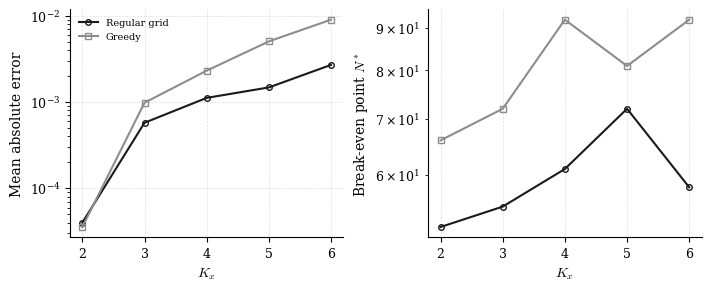

In [61]:
# (A) Fixed number of snapshots: mean error and break-even point vs Kx, regular vs greedy

rows = []
for Kx in Kx_tab:
    t_LP = hf_test_K[Kx]["time"].mean()
    r = reg_res[(Kx, m_P[Kx])]
    g = next(x for x in greedy_res[Kx] if x["P"] == P_target)
    rows.append({"Kx": Kx,
                 "P (reg.)": r["P"], "N* (reg.)": break_even(r["T_off"], t_LP, r["t_RB"]),
                 "Mean err. (reg.)": r["err_mean"], "Max err. (reg.)": r["err_max"],
                 "P (greedy)": g["P"], "N* (greedy)": break_even(g["T_off"], t_LP, g["t_RB"]),
                 "Mean err. (greedy)": g["err_mean"], "Max err. (greedy)": g["err_max"]})
table_A = pd.DataFrame(rows).set_index("Kx")
display(table_A)
latex_rows(table_A, int_cols=("P (reg.)", "N* (reg.)", "P (greedy)", "N* (greedy)"))

plt.close("all")
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), constrained_layout=True)
for col, marker, grey, label in [("reg.", "o", "0.1", "Regular grid"), ("greedy", "s", "0.55", "Greedy")]:
    axes[0].plot(table_A.index, table_A[f"Mean err. ({col})"], color=grey, lw=1.5, marker=marker, ms=4, mfc="none", label=label)
    axes[1].plot(table_A.index, table_A[f"N* ({col})"], color=grey, lw=1.5, marker=marker, ms=4, mfc="none", label=label)
axes[0].set_ylabel("Mean absolute error")
axes[1].set_ylabel("Break-even point $N^*$")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("$K_x$")
    ax.set_xticks(Kx_tab)
    ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].legend(frameon=False, fontsize=7)
fig.savefig(os.path.join(fig_dir, "Kx_fixed_P.pdf"), bbox_inches="tight")
plt.show()

,P (reg.),Fill dist. (reg.),N* (reg.),Mean err. (reg.),Max err. (reg.),P (greedy),N* (greedy),Mean err. (greedy),Max err. (greedy)
Kx,,,,,,,,,
2,11,0.070702,11.0,0.001114,0.003493,13.0,15.0,0.001046,0.002724
3,66,0.081417,66.0,0.000477,0.001477,86.0,111.0,0.000472,0.000973
4,286,0.097278,302.0,0.000234,0.000905,NaN,NaN,NaN,NaN
5,1001,0.104865,1010.0,0.000132,0.000407,NaN,NaN,NaN,NaN


% Kx & P (reg.) & Fill dist. (reg.) & N* (reg.) & Mean err. (reg.) & Max err. (reg.) & P (greedy) & N* (greedy) & Mean err. (greedy) & Max err. (greedy)
2 & 11 & 7.07e-02 & 11 & 1.11e-03 & 3.49e-03 & 13 & 15 & 1.05e-03 & 2.72e-03 \\
3 & 66 & 8.14e-02 & 66 & 4.77e-04 & 1.48e-03 & 86 & 111 & 4.72e-04 & 9.73e-04 \\
4 & 286 & 9.73e-02 & 302 & 2.34e-04 & 9.05e-04 & -- & -- & -- & -- \\
5 & 1001 & 1.05e-01 & 1010 & 1.32e-04 & 4.07e-04 & -- & -- & -- & -- \\


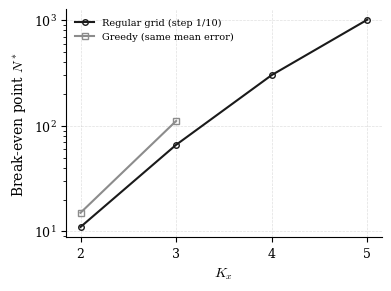

In [62]:
# (B) Regular grid with fixed step 1/m_h vs smallest greedy basis reaching the same mean error

rows = []
for Kx in Kx_tab_h:
    t_LP = hf_test_K[Kx]["time"].mean()
    r = reg_res[(Kx, m_h)]
    g = next((x for x in greedy_res[Kx] if x["err_mean"] <= r["err_mean"]), None)
    rows.append({"Kx": Kx,
                 "P (reg.)": r["P"], "Fill dist. (reg.)": r["fill"],
                 "N* (reg.)": break_even(r["T_off"], t_LP, r["t_RB"]),
                 "Mean err. (reg.)": r["err_mean"], "Max err. (reg.)": r["err_max"],
                 "P (greedy)": g["P"] if g else np.nan,
                 "N* (greedy)": break_even(g["T_off"], t_LP, g["t_RB"]) if g else np.nan,
                 "Mean err. (greedy)": g["err_mean"] if g else np.nan,
                 "Max err. (greedy)": g["err_max"] if g else np.nan})
table_B = pd.DataFrame(rows).set_index("Kx")
display(table_B)
latex_rows(table_B, int_cols=("P (reg.)", "N* (reg.)", "P (greedy)", "N* (greedy)"))

plt.close("all")
fig, ax = plt.subplots(figsize=(3.8, 2.8), constrained_layout=True)
ax.plot(table_B.index, table_B["N* (reg.)"], color="0.1", lw=1.5, marker="o", ms=4, mfc="none", label=f"Regular grid (step 1/{m_h})")
ax.plot(table_B.index, table_B["N* (greedy)"], color="0.55", lw=1.5, marker="s", ms=4, mfc="none", label="Greedy (same mean error)")
ax.set_yscale("log")
ax.set_xlabel("$K_x$")
ax.set_xticks(Kx_tab_h)
ax.set_ylabel("Break-even point $N^*$")
ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=7)
fig.savefig(os.path.join(fig_dir, "Kx_fixed_fill_distance.pdf"), bbox_inches="tight")
plt.show()

In [104]:
# Regular and greedy models at about the same numbers of snapshots for every Kx

P_targets = [n**2 for n in [2, 4, 6, 8, 10]]          # 4, 16, 36, 64, 100


def closest_m(Kx, P):
    """Step 1/m of the simplex grid whose size is closest to P."""
    return min(range(1, 200), key=lambda m: abs(comb(m + Kx - 1, Kx - 1) - P))


reg_curve, greedy_curve = {}, {}
for Kx in Kx_tab:
    # Regular grids: closest size to each target (duplicates removed)
    m_list = sorted({closest_m(Kx, P) for P in P_targets})
    reg_curve[Kx] = []
    for m in m_list:
        model = build_regular(Kx, m)                     # cached
        reg_curve[Kx].append({**eval_rb(model["Lam"], model["W"], Kx), "P": model["W"].size})

    # Greedy: exactly the target sizes (at least the Kx vertices)
    g = greedy_K[Kx]
    P_list = sorted({max(P, Kx) for P in P_targets if P <= g["W"].size})
    greedy_curve[Kx] = [{**eval_rb(g["Lam"][:, :P], g["W"][:P], Kx), "P": P} for P in P_list]

    print(f"Kx = {Kx}: regular sizes {[x['P'] for x in reg_curve[Kx]]} | greedy sizes {P_list}")

Computed and saved saved_Kx/reg_Kx2_m3_N100.npz
Computed and saved saved_Kx/reg_Kx2_m15_N100.npz
Computed and saved saved_Kx/reg_Kx2_m35_N100.npz
Computed and saved saved_Kx/reg_Kx2_m63_N100.npz
Computed and saved saved_Kx/reg_Kx2_m99_N100.npz
Kx = 2: regular sizes [4, 16, 36, 64, 100] | greedy sizes [4, 16, 36, 64, 100]
Computed and saved saved_Kx/reg_Kx3_m1_N100.npz
Computed and saved saved_Kx/reg_Kx3_m4_N100.npz
Computed and saved saved_Kx/reg_Kx3_m7_N100.npz
Loaded saved_Kx/reg_Kx3_m10_N100.npz
Computed and saved saved_Kx/reg_Kx3_m13_N100.npz
Kx = 3: regular sizes [3, 15, 36, 66, 105] | greedy sizes [4, 16, 36, 64, 100]
Computed and saved saved_Kx/reg_Kx4_m1_N100.npz
Computed and saved saved_Kx/reg_Kx4_m3_N100.npz
Computed and saved saved_Kx/reg_Kx4_m4_N100.npz
Loaded saved_Kx/reg_Kx4_m5_N100.npz
Computed and saved saved_Kx/reg_Kx4_m6_N100.npz
Kx = 4: regular sizes [4, 20, 35, 56, 84] | greedy sizes [4, 16, 36, 64, 100]
Computed and saved saved_Kx/reg_Kx5_m1_N100.npz
Computed and s

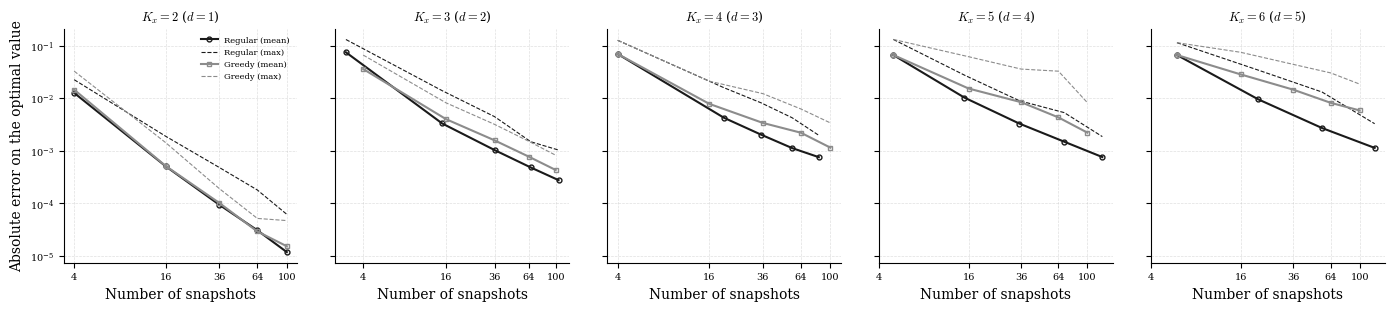

In [105]:
# Mean and max error vs number of snapshots, one panel per Kx: regular grid vs greedy

plt.close("all")
fig, axes = plt.subplots(1, len(Kx_tab), figsize=(2.8 * len(Kx_tab), 3), constrained_layout=True, sharey=True)

for ax, Kx in zip(axes, Kx_tab):
    for res, grey, marker, name in [(reg_curve[Kx], "0.1", "o", "Regular"), (greedy_curve[Kx], "0.55", "s", "Greedy")]:
        P_list = [x["P"] for x in res]
        ax.plot(P_list, [x["err_mean"] for x in res], color=grey, lw=1.5, marker=marker, ms=3.5, mfc="none",
                label=f"{name} (mean)")
        ax.plot(P_list, [x["err_max"] for x in res], color=grey, lw=0.8, ls="--", label=f"{name} (max)")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(P_targets)
    ax.set_xticklabels(P_targets)
    ax.minorticks_off()
    ax.set_title(f"$K_x = {Kx}$ ($d = {Kx - 1}$)", fontsize=9)
    ax.set_xlabel("Number of snapshots")
    ax.set_box_aspect(1)
    ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=7)

axes[0].set_ylabel("Absolute error on the optimal value")
axes[0].legend(frameon=False, fontsize=6)
fig.savefig(os.path.join(fig_dir, "Kx_error_vs_snapshots.pdf"), bbox_inches="tight")
plt.show()